# dsQTL by peak specificity, with cross-cell-type controls

Four panels, in talk order:

1. **Pooled** AUPRC over every scorable variant, the twelve GM12878 arms -- the number before any stratification.
2. **Stratified** into low- and high-specificity GM12878 peaks, same twelve arms. This is IGVF panel 5.
3. **Pooled**, reduced to the four base GM12878 arms and their HepG2-scored twins.
4. **Stratified**, same eight arms.

Panels 3 and 4 are the argument: every HepG2 arm is a GM12878-trained model scored against
HepG2 tracks, so it cannot know anything cell-type specific about this LCL dsQTL set. If the
cell-type-specific signal is what carries the high-specificity stratum, the HepG2 twin should
collapse there and survive on the broad, generic peaks.

## What this notebook does and does not touch

Nothing here modifies `dsQTL_benchmark8`. The twelve existing arms are read straight out of the
`model_scores.npz` it already built; the four HepG2 arms are scored into their own cache file.
`ARMS` and `scores_manifest.json` are left alone, so IGVF panel 5 keeps exactly the numbers it
has today.

The one exception is `annotate_variants`, which rewrites `variant_specificity.tsv.gz` every time
it is called. It is deterministic given the same variants and the same peak cache, so the file it
writes is byte-identical to the one already there.

Run top to bottom. The only slow cell is the one that scores the four new arms -- one 1.7 GB
Borzoi array read strided, plus 17,506 AlphaGenome chunks read one at a time. It caches to
`dsQTL_benchmark8_cache/hepg2_arm_scores.npz` and is instant on every later run.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

DSQTL_DIR = Path('/data1/lesliec/sarthak/caduceus/notebooks/benchmarks/dsqtl')
FIG_DIR = Path('/data1/lesliec/sarthak/caduceus/notebooks/figures')
sys.path[:0] = [str(DSQTL_DIR), str(FIG_DIR)]

# dsQTL_benchmark8_analysis calls matplotlib.use('Agg') at import time, so the
# %matplotlib inline below has to come after it or no figure renders in the notebook.
from dsQTL_benchmark8_analysis import (ARMS, CACHE, DSQ, map_variants, annotate_variants,
                                       metric_values, metadata, read_chunk)
import igvf_arms as A

%matplotlib inline
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

NEW_SCORES = CACHE / 'hepg2_arm_scores.npz'
NEW_MANIFEST = CACHE / 'hepg2_arm_manifest.json'

print('cache            :', CACHE)
print('arms already scored :', len(ARMS))
print('new-arm cache    :', 'built' if NEW_SCORES.exists() else 'NOT BUILT -- the scoring cell will build it')

cache            : /data1/lesliec/sarthak/caduceus/notebooks/benchmarks/dsqtl/dsQTL_benchmark8_cache
arms already scored : 12
new-arm cache    : built


---
## The four new arms

Each one is a GM12878-trained model scored against HepG2 tracks, paired with the GM12878 arm it
is the control for. All four are shape-compatible with the existing scoring code and need no
changes to it: the window slicing keys off substrings in the filename (`borzoi` -> bins
3040:3104, `enformer` -> bins 440:456, `.zarr` -> the AlphaGenome chunk reader), and the
cis-Mamba array has no substring match so it uses its full 500-bin window, exactly as the
GM12878 cis-Mamba arm does.

| family | GM12878 arm (already scored) | HepG2-eval arm (new) | shape |
|---|---|---|---|
| cis-Mamba | `nomlm_maskonly.npy` | `nomlm_maskonly_gm12878trained_hepg2eval.npy` | (17506, 500, 2) |
| Enformer | `enformer_dsqtl.npy` | `enformer_dsqtl_hepg2eval.npy` | (17506, 896, 2) |
| Borzoi | `borzoi_dsqtl_pretrained_1288.npy` | `borzoi_dsqtl_pretrained_1303.npy` | (17506, 6144, 2) |
| AlphaGenome | `alphagenome_dsqtl.zarr` | `alphagenome_dsqtl_hepg2score.zarr` | (17506, 1000, 2) |

The score is the same one the benchmark uses throughout: `|log2(mean_ref / mean_alt)|` over the
centre window, with a variant marked unscorable if either mean is zero.

In [2]:
# Track 1303 is taken to be the HepG2 counterpart of the GM12878 track 1288 used by the
# existing pretrained-Borzoi arm. If that is the wrong track, only the label needs changing.
NEW_ARMS = [
    ('cis-Mamba (HepG2 eval)',   'ours',        'nomlm_maskonly_gm12878trained_hepg2eval.npy'),
    ('Enformer (HepG2 eval)',    'enformer',    'enformer_dsqtl_hepg2eval.npy'),
    ('Borzoi (HepG2 eval)',      'borzoi',      'borzoi_dsqtl_pretrained_1303.npy'),
    ('AlphaGenome (HepG2 eval)', 'alphagenome', 'alphagenome_dsqtl_hepg2score.zarr'),
]


def score_new_arms(q):
    """Score the HepG2 arms exactly as `score_variants` scores the others.

    Deliberately a separate npz. Appending these to ARMS would break the equality
    assert on scores_manifest.json and force all twelve existing arms to be re-read
    from disk, which is an hour of I/O to recompute numbers that have not changed.
    """
    paths = [DSQ / f for _, _, f in NEW_ARMS]
    provenance = dict(version=1, arms=NEW_ARMS,
                      files=[dict(path=str(p), size=p.stat().st_size, mtime_ns=p.stat().st_mtime_ns)
                             for p in paths])
    # Round-trip so tuples compare equal against the cached copy, as score_variants does.
    provenance = json.loads(json.dumps(provenance))
    if NEW_SCORES.exists():
        assert json.loads(NEW_MANIFEST.read_text()) == provenance, (
            'a source array changed -- delete hepg2_arm_scores.npz and hepg2_arm_manifest.json to rescore')
        with np.load(NEW_SCORES) as d:
            return d['scores'], d['scorable']

    scores = np.full((len(q), len(NEW_ARMS)), np.nan)
    scorable = np.zeros_like(scores, dtype=bool)
    for i, (name, family, f) in enumerate(NEW_ARMS):
        if f.endswith('.zarr'):
            # AlphaGenome is one variant per chunk, same layout as the GM12878 store.
            m = metadata(DSQ / f)
            assert m['shape'][0] == len(q) and m['chunks'] == [1, m['shape'][1], 2]
            a = np.empty(m['shape'], dtype=m['dtype'])
            for j in range(len(q)):
                a[j] = read_chunk(DSQ / f, m, (j, 0, 0))[0]
        else:
            a = np.load(DSQ / f, mmap_mode='r')
        assert a.ndim == 3 and a.shape[0] == len(q) and a.shape[2] == 2
        if 'borzoi' in f:
            assert a.shape[1] == 6144
            a = a[:, 3040:3104, :]
        elif 'enformer' in f:
            assert a.shape[1] == 896
            a = a[:, 440:456, :]
        a = np.asarray(a, dtype=np.float64)
        assert np.isfinite(a).all() and (a >= 0).all(), name
        means = a.mean(axis=1)
        ok = (means[:, 0] > 0) & (means[:, 1] > 0)
        s = np.zeros(len(q))
        s[ok] = np.abs(np.log2(means[ok, 0] / means[ok, 1]))
        scores[:, i] = s
        scorable[:, i] = ok & np.isfinite(s)
        print(f'{name:26s} scorable {int(scorable[:, i].sum()):6d} / {len(q)}', flush=True)
    np.savez_compressed(NEW_SCORES, scores=scores, scorable=scorable)
    NEW_MANIFEST.write_text(json.dumps(provenance, indent=2))
    return scores, scorable

### Score them

Slow on the first run only. Watch the printed `scorable` counts: every one of the twelve existing
arms scores all 17,506 variants, so if these four do too, nothing is dropped from any panel and
the pooled n stays at the full 17,506.

In [3]:
q = map_variants()

with np.load(CACHE / 'model_scores.npz') as d:
    base_scores, base_scorable = d['scores'], d['scorable']
assert base_scores.shape == (len(q), len(ARMS))

new_scores, new_scorable = score_new_arms(q)

SCORES = np.hstack([base_scores, new_scores])
SCORABLE = np.hstack([base_scorable, new_scorable])
ALL_ARMS = list(ARMS) + NEW_ARMS

BASE = list(range(len(ARMS)))                          # the twelve GM12878 arms
NEW = [len(ARMS) + i for i in range(len(NEW_ARMS))]    # the four HepG2 arms
# Panels 3 and 4: the four base GM12878 arms, each followed by its HepG2 twin.
REDUCED = [0, NEW[0], 1, NEW[1], 3, NEW[2], 7, NEW[3]]

print()
for i in NEW:
    print(f'{ALL_ARMS[i][0]:26s} scorable {int(SCORABLE[:, i].sum()):6d} / {len(q)}')
print()
print('variants                       ', len(q))
print('common support, 12 base arms   ', int(SCORABLE[:, BASE].all(axis=1).sum()))
print('common support, 8 reduced arms ', int(SCORABLE[:, REDUCED].all(axis=1).sum()))
print('common support, all 16 arms    ', int(SCORABLE.all(axis=1).sum()))
print()
for i in REDUCED:
    print(f'  {"HepG2" if i in NEW else "GM12878":8s} {ALL_ARMS[i][0]}')


cis-Mamba (HepG2 eval)     scorable  17506 / 17506
Enformer (HepG2 eval)      scorable  17506 / 17506
Borzoi (HepG2 eval)        scorable  17506 / 17506
AlphaGenome (HepG2 eval)   scorable  17506 / 17506

variants                        17506
common support, 12 base arms    17506
common support, 8 reduced arms  17506
common support, all 16 arms     17506

  GM12878  cis-Mamba (GM12878 DNase logFC)
  HepG2    cis-Mamba (HepG2 eval)
  GM12878  Enformer (pretrained)
  HepG2    Enformer (HepG2 eval)
  GM12878  Borzoi (pretrained)
  HepG2    Borzoi (HepG2 eval)
  GM12878  AlphaGenome
  HepG2    AlphaGenome (HepG2 eval)


---
## Specificity annotation

`annotate_variants` assigns each variant to a GM12878 peak and labels that peak by breadth --
how many DNase tracks call it. Peaks at or below the genome-wide median breadth are
**high specificity** (few cell types have them), above it are **low specificity** (generic, nearly
everyone has them). Variants that map to no GM12878 peak fall in `outside_GM12878_peaks` and
appear only in the pooled panels.

The split is a property of the variant, not of any model, so adding the HepG2 arms cannot move
it: the strata keep the same membership, the same n and the same positive counts they have in
`stratified_metrics.tsv`.

In [4]:
v = annotate_variants(q)

DEFINITION = 'merged'   # 'bins' is the 128-bp-bin peak definition; see the last cell
MEDIAN = int(pd.read_csv(CACHE / f'gm12878_{DEFINITION}.tsv.gz', sep='\t',
                         usecols=['median_breadth']).median_breadth.iloc[0])
MASK_ALL = np.ones(len(v), dtype=bool)

label = v.label_binary.to_numpy()
print(f'definition = {DEFINITION}, median breadth = {MEDIAN} tracks')
print()
counts = v[f'{DEFINITION}_specificity'].value_counts()
for group in ['high_specificity', 'low_specificity', 'outside_GM12878_peaks', 'unmapped']:
    if group in counts:
        m = v[f'{DEFINITION}_specificity'].eq(group).to_numpy()
        print(f'  {group:22s} n = {int(m.sum()):6,}   positives = {int(label[m].sum()):4d}   '
              f'prevalence = {label[m].mean():.4f}')
print(f'  {"pooled (all)":22s} n = {len(v):6,}   positives = {int(label.sum()):4d}   '
      f'prevalence = {label.mean():.4f}')

definition = merged, median breadth = 68 tracks

  high_specificity       n =    834   positives =   38   prevalence = 0.0456
  low_specificity        n = 11,338   positives =  366   prevalence = 0.0323
  outside_GM12878_peaks  n =  5,333   positives =   31   prevalence = 0.0058
  unmapped               n =      1   positives =    0   prevalence = 0.0000
  pooled (all)           n = 17,506   positives =  435   prevalence = 0.0248


---
## Plotting

Panel 5 conventions: horizontal bars in family colours, value printed at the bar end, no error
bars. The HepG2 twin of a family is the same hue blended toward white, so a pair reads as a pair.

Two deliberate departures from panel 5. The x axis starts at 0 rather than 0.30, and the dotted
line is the stratum's prevalence -- which is where AUPRC's chance level actually sits. It matters
here because the two strata do not share a chance level (merged: 0.046 high vs 0.032 low), so a
bar that looks taller is not automatically doing better. Set `xmin=0.30` in `bars` to get the
zoomed panel-5 axis back.

`common` is intersected over the arms in the panel being drawn, so each panel grades its own arms
on identical variants and an arm that is absent from a panel cannot remove variants from it.

In [5]:
def lighten(hexcolor, amount=0.55):
    """Blend a family hue toward white -- the HepG2 twin of the GM12878 colour."""
    c = np.array([int(hexcolor[i:i + 2], 16) for i in (1, 3, 5)]) / 255
    return tuple(c + (1 - c) * amount)


def arm_color(i):
    base = A.FAMILY[ALL_ARMS[i][1]]
    return lighten(base) if i in NEW else base


def ap_table(arm_idx, mask):
    """AUPRC per arm on one variant set, with the set's size and chance level attached."""
    arm_idx = list(arm_idx)
    common = SCORABLE[:, arm_idx].all(axis=1)
    sel = np.flatnonzero(np.asarray(mask) & common)
    y = v.label_binary.to_numpy()[sel]
    assert np.unique(y).size == 2, 'this variant set has only one class'
    tab = pd.DataFrame([dict(idx=i, name=ALL_ARMS[i][0], family=ALL_ARMS[i][1],
                             AP=metric_values(y, SCORES[sel, i])[0])
                        for i in arm_idx])
    tab.attrs.update(n=len(sel), positives=int(y.sum()), prevalence=float(y.mean()))
    return tab


def bars(ax, tab, title, xmin=0.0, xmax=None):
    xmax = xmax if xmax is not None else np.ceil((tab.AP.max() + 0.06) * 20) / 20
    y = np.arange(len(tab))
    ax.barh(y, tab.AP.to_numpy() - xmin, left=xmin, height=0.62, zorder=3,
            color=[arm_color(i) for i in tab.idx], edgecolor='none')
    for row, value in enumerate(tab.AP):
        ax.text(value + (xmax - xmin) * 0.01, row, f'{value:.3f}', va='center', ha='left',
                fontsize=11, color='#333333')
    ax.axvline(tab.attrs['prevalence'], color=A.C_REF, ls=':', lw=1.3, zorder=4)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(len(y) - 0.4, -0.8)
    ax.set_yticks(y, tab.name.tolist())
    ax.tick_params(axis='y', length=0, pad=10, labelsize=12)
    ax.tick_params(axis='x', labelsize=12)
    ax.xaxis.set_major_locator(MultipleLocator(0.1))
    ax.grid(axis='x', color='#E9E9E9', linewidth=0.7, zorder=0)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.set_title(title, loc='left', fontsize=15, weight='semibold', pad=32)
    ax.text(0, 1.015, f"n = {tab.attrs['n']:,}  ·  {tab.attrs['positives']} dsQTLs  ·  "
                      f"chance = {tab.attrs['prevalence']:.3f}",
            transform=ax.transAxes, ha='left', va='bottom', color='#666666', fontsize=11)
    ax.set_xlabel('AUPRC (average precision); dotted line is chance', fontsize=12, labelpad=8)
    return ax


def pooled_panel(arm_idx, title):
    tab = ap_table(arm_idx, MASK_ALL)
    fig, ax = plt.subplots(figsize=(11.0, 0.52 * len(tab) + 2.6))
    fig.subplots_adjust(left=0.34, right=0.97, top=0.80, bottom=0.16)
    bars(ax, tab, title)
    return tab


def stratified_panel(arm_idx, title, definition=None):
    definition = definition or DEFINITION
    groups = [('low_specificity', 'Low specificity', '>'),
              ('high_specificity', 'High specificity', '≤')]
    tabs = [ap_table(arm_idx, v[f'{definition}_specificity'].eq(g).to_numpy()) for g, _, _ in groups]
    xmax = np.ceil((max(t.AP.max() for t in tabs) + 0.06) * 20) / 20
    fig, axes = plt.subplots(1, 2, figsize=(15.5, 0.52 * len(arm_idx) + 2.9),
                             sharex=True, sharey=True)
    fig.subplots_adjust(left=0.235, right=0.98, top=0.78, bottom=0.17, wspace=0.10)
    for ax, tab, (_, name, rel) in zip(axes, tabs, groups):
        bars(ax, tab, f'{name}   ({rel}{MEDIAN} tracks)', xmax=xmax)
    fig.suptitle(title, x=0.235, y=0.985, ha='left', fontsize=18, weight='semibold')
    return pd.concat([t.assign(stratum=g) for t, (g, _, _) in zip(tabs, groups)], ignore_index=True)


# --- log-scale histogram helpers --------------------------------------------
# Density normalisation is wrong on log-spaced bins: it divides each count by bin width,
# and the
# leftmost bin is orders of magnitude narrower than the rightmost. A handful of values
# clipped onto the left edge then becomes a spike hundreds of times taller than the real
# distribution -- in the observed HepG2 panel, 193 exact zeros produced a bin 620x the
# height of the median. These plot fraction-per-bin instead, and say what was clipped.
def log_bins(*arrays, nbins=60, floor_q=0.01):
    """Log-spaced bins whose left edge is a low quantile of the positive values.

    Taking the minimum instead puts the left edge far below the bulk of the data, which
    is what makes the first bin pathologically narrow.
    """
    finite = [np.asarray(a)[np.isfinite(a)] for a in arrays]
    pos = np.concatenate([x[x > 0] for x in finite])
    lo = float(np.quantile(pos, floor_q))
    hi = float(max(np.concatenate(finite).max(), lo * 10))
    return np.logspace(np.log10(lo), np.log10(hi), nbins)


def frac_hist(ax, values, bins, **kw):
    """Histogram as fraction of values per bin. Returns the fraction clipped left."""
    x = np.asarray(values)[np.isfinite(values)]
    ax.hist(np.clip(x, bins[0], bins[-1]), bins=bins,
            weights=np.full(len(x), 1.0 / len(x)), **kw)
    return float((x <= bins[0]).mean())


def note_clipped(ax, bins, **named):
    """State what landed on the left edge, since a log axis cannot show zeros."""
    parts = []
    for name, values in named.items():
        x = np.asarray(values)[np.isfinite(values)]
        frac = (x <= bins[0]).mean()
        if frac >= 0.005:
            parts.append(f'{100 * frac:.0f}% {name}')
    if parts:
        ax.text(0.02, 0.97, 'at/below axis floor: ' + ', '.join(parts), transform=ax.transAxes,
                ha='left', va='top', fontsize=8, color='#B03A2E')


---
## 1 - Pooled, all twelve GM12878 arms

Every scorable variant, no stratification. This is the number the field would report, and it is
the one the rest of the notebook takes apart. It includes the variants that fall outside any
GM12878 peak, which is why n here is larger than the two strata added together.

,name,AP
7,AlphaGenome,0.626323
1,Enformer (pretrained),0.578646
11,ChromBPNet (GM12878 ATAC IPS),0.563892
0,cis-Mamba (GM12878 DNase logFC),0.550809
4,Borzoi LoRA (GM12878),0.547103
3,Borzoi (pretrained),0.538394
5,Borzoi full FT (GM12878),0.535627
2,Enformer retrained (GM12878),0.490364
10,ChromBPNet (GM12878 ATAC logFC),0.490081
9,ChromBPNet (GM12878 DNase IPS),0.442331


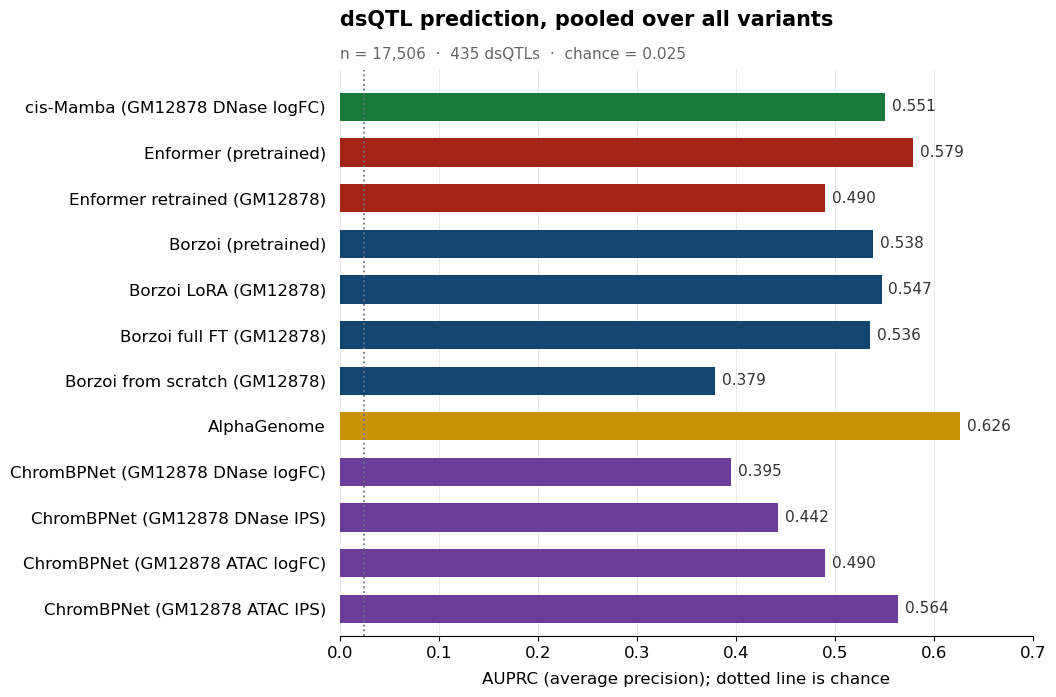

In [6]:
pooled_all = pooled_panel(BASE, 'dsQTL prediction, pooled over all variants')
pooled_all[['name', 'AP']].sort_values('AP', ascending=False)

---
## 2 - Stratified by peak specificity, all twelve arms

Same arms, same metric, same variants -- split by whether the GM12878 peak the variant sits in is
generic (called in many cell types) or specific (called in few). This reproduces IGVF panel 5;
the AP values should match `stratified_metrics.tsv` exactly, since the arm set and the common
support are unchanged.

stratum,high_specificity,low_specificity
name,,
AlphaGenome,0.603607,0.641156
Borzoi (pretrained),0.553394,0.537324
Borzoi LoRA (GM12878),0.570878,0.541497
Borzoi from scratch (GM12878),0.330361,0.373636
Borzoi full FT (GM12878),0.480683,0.544892
ChromBPNet (GM12878 ATAC IPS),0.599211,0.558910
ChromBPNet (GM12878 ATAC logFC),0.612074,0.490623
ChromBPNet (GM12878 DNase IPS),0.484228,0.435033
ChromBPNet (GM12878 DNase logFC),0.514726,0.393663


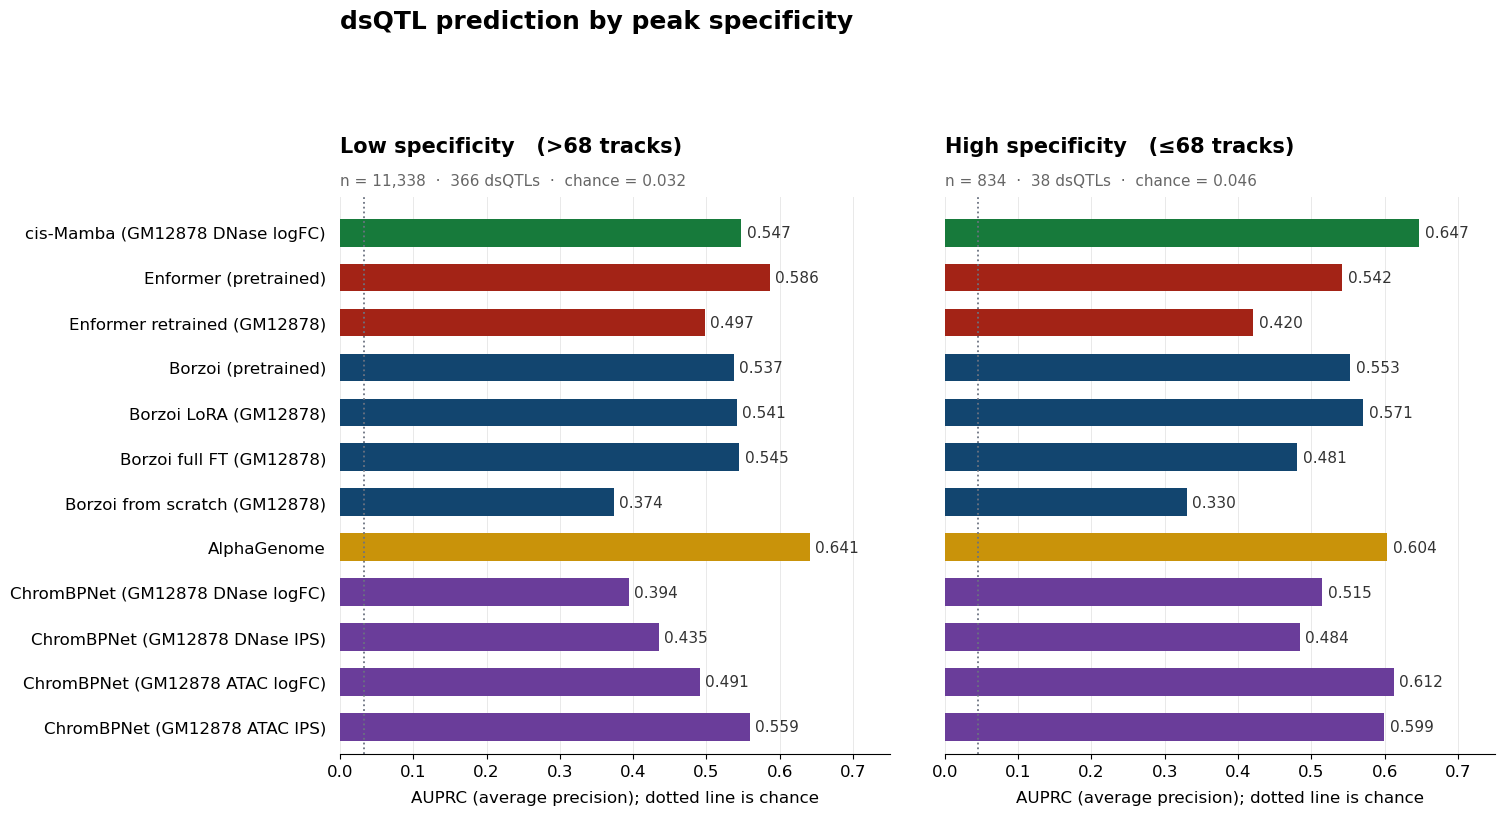

In [7]:
strat_all = stratified_panel(BASE, 'dsQTL prediction by peak specificity')
strat_all.pivot(index='name', columns='stratum', values='AP')

---
## 3 - Pooled, base arms against their HepG2 twins

Reduced to the four base GM12878 arms and, beside each, the same model scored on HepG2 tracks.
Everything finetuned on GM12878 is gone, and so is ChromBPNet -- what is left is four pairs that
differ only in which cell type's tracks the prediction was read out of.

Pooled, a HepG2 arm should not be catastrophically worse: most of these variants sit in broad
peaks that HepG2 shares with GM12878.

,name,readout,AP
0,cis-Mamba (GM12878 DNase logFC),GM12878,0.550809
1,cis-Mamba (HepG2 eval),HepG2,0.517356
2,Enformer (pretrained),GM12878,0.578646
3,Enformer (HepG2 eval),HepG2,0.300224
4,Borzoi (pretrained),GM12878,0.538394
5,Borzoi (HepG2 eval),HepG2,0.304269
6,AlphaGenome,GM12878,0.626323
7,AlphaGenome (HepG2 eval),HepG2,0.293208


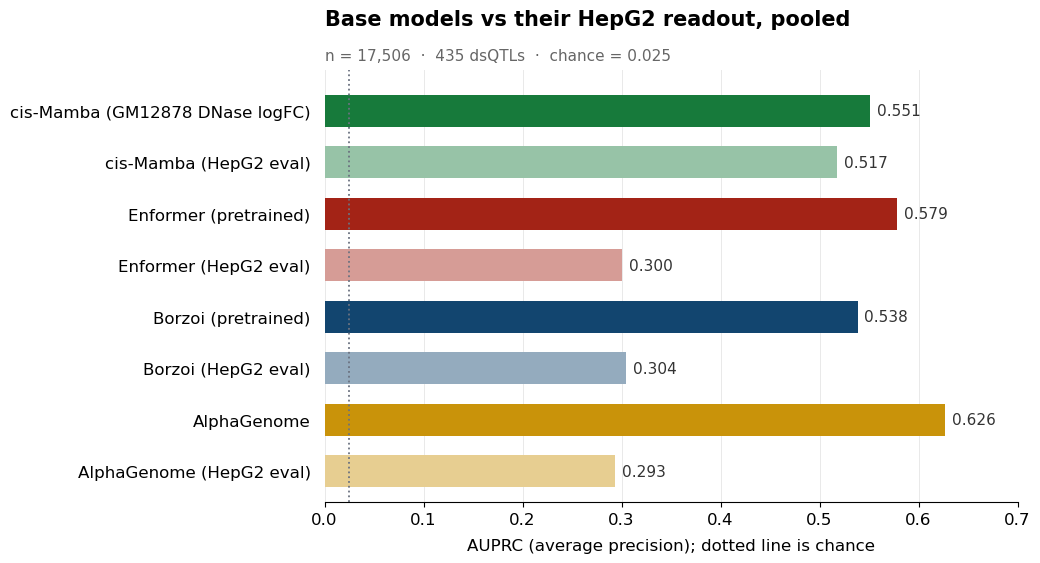

In [8]:
pooled_reduced = pooled_panel(REDUCED, 'Base models vs their HepG2 readout, pooled')
pooled_reduced.assign(readout=np.where(pooled_reduced.idx.isin(NEW), 'HepG2', 'GM12878'))[
    ['name', 'readout', 'AP']]

---
## 4 - Stratified, base arms against their HepG2 twins

The panel the argument rests on. Read each pair, not each bar: the gap between a GM12878 arm and
its HepG2 twin is how much of that arm's performance needed the right cell type. If the
high-specificity stratum is where cell-type-specific sequence signal lives, the pair should open
up there and close on the low-specificity side.

A HepG2 arm that holds up on low specificity and falls on high specificity is the clean result.
A HepG2 arm that holds up on *both* says the corresponding GM12878 arm was never using
cell-type-specific information in the first place.

stratum,high_specificity,low_specificity,high_minus_low
name,,,
cis-Mamba (GM12878 DNase logFC),0.647328,0.547320,0.100007
cis-Mamba (HepG2 eval),0.620727,0.507729,0.112998
Enformer (pretrained),0.542442,0.586030,-0.043588
Enformer (HepG2 eval),0.105757,0.329242,-0.223486
Borzoi (pretrained),0.553394,0.537324,0.016069
Borzoi (HepG2 eval),0.127468,0.331854,-0.204386
AlphaGenome,0.603607,0.641156,-0.037549
AlphaGenome (HepG2 eval),0.118079,0.336165,-0.218086


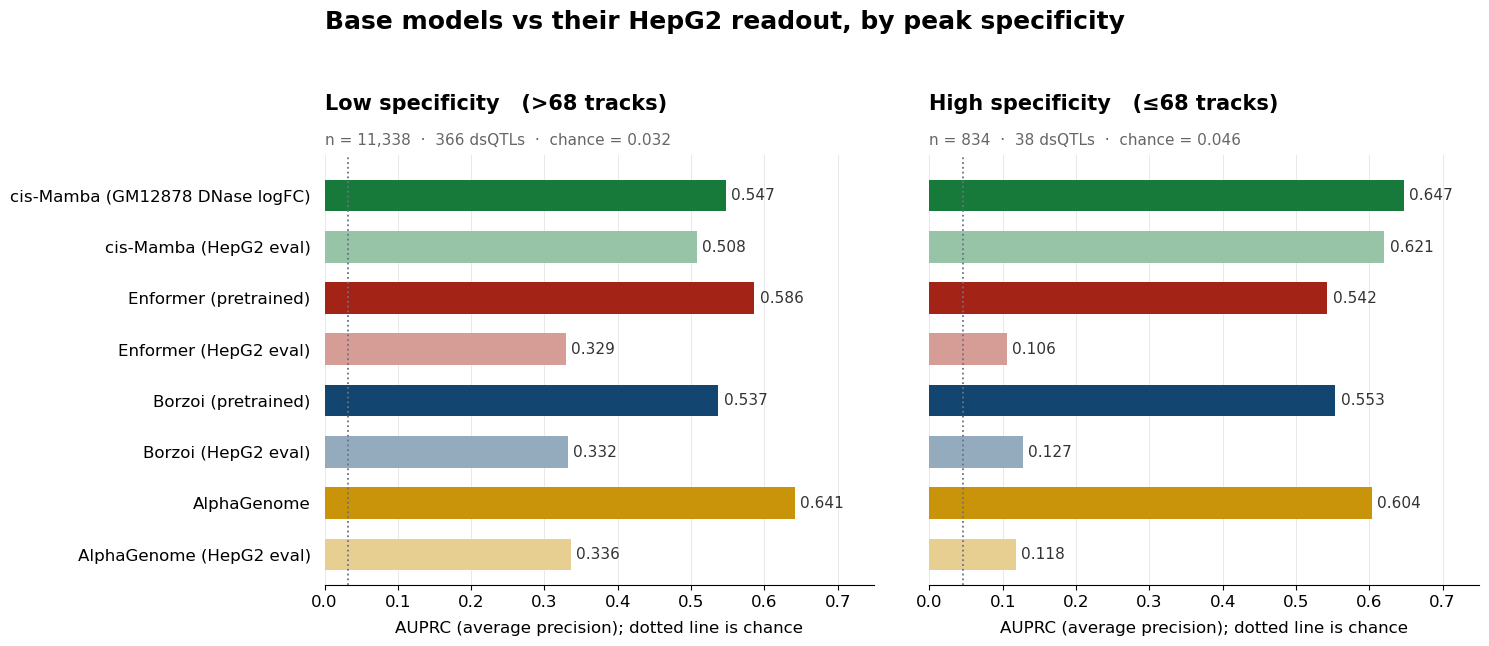

In [9]:
strat_reduced = stratified_panel(REDUCED, 'Base models vs their HepG2 readout, by peak specificity')
wide = strat_reduced.pivot(index='name', columns='stratum', values='AP')
wide['high_minus_low'] = wide.high_specificity - wide.low_specificity
wide.reindex([ALL_ARMS[i][0] for i in REDUCED])

---
## Pair gaps

The same four panels reduced to one table: for each family, how far the HepG2 readout falls
behind the GM12878 one, pooled and in each stratum. A larger drop in the high-specificity column
than in the low-specificity column is the claim.

In [10]:
rows = []
for gm, hep in zip(REDUCED[::2], REDUCED[1::2]):
    pooled = pooled_reduced.set_index('idx').AP
    row = dict(family=ALL_ARMS[gm][1],
               pooled=pooled[gm] - pooled[hep])
    for group in ['low_specificity', 'high_specificity']:
        d = strat_reduced[strat_reduced.stratum == group].set_index('idx').AP
        row[group] = d[gm] - d[hep]
    rows.append(row)
gaps = pd.DataFrame(rows).set_index('family')
gaps['specific_minus_generic'] = gaps.high_specificity - gaps.low_specificity
gaps.round(4)

,pooled,low_specificity,high_specificity,specific_minus_generic
family,,,,
ours,0.0335,0.0396,0.0266,-0.0130
enformer,0.2784,0.2568,0.4367,0.1799
borzoi,0.2341,0.2055,0.4259,0.2205
alphagenome,0.3331,0.3050,0.4855,0.1805


---
## Knobs

| what | where |
|---|---|
| the other peak definition | `DEFINITION = 'bins'` in the annotation cell, then re-run from there. `bins` uses 128-bp bins rather than merged peaks; its median breadth is 108 and it puts far more variants in the high-specificity stratum |
| panel-5 zoomed x axis | pass `xmin=0.30` through `bars`; the chance line then falls off the left of the axis |
| add an arm back | append its index to `REDUCED` (ChromBPNet is 8-11, the retrained/finetuned arms are 2 and 4-6) |
| rescore after a file changes | delete `hepg2_arm_scores.npz` and `hepg2_arm_manifest.json`; the manifest assert will tell you if you forget |
| Borzoi HepG2 track | `NEW_ARMS`, third entry -- track 1303 is assumed to be the HepG2 counterpart of 1288 |

Two things this notebook does not do, both on purpose: no bootstrap confidence intervals (the
high-specificity stratum rests on 38 positives, so treat small gaps there as noise -- the 200-draw
cluster bootstrap in `stratified_metrics` is the place to get them), and no writes to
`stratified_metrics.tsv` or the IGVF figure cache.

---
# 5 - Is it the peak, or the variant?

The pair gaps above say a HepG2 readout costs Enformer, Borzoi and AlphaGenome 0.2-0.49 AP while
costing cis-Mamba almost nothing. There are two very different reasons a HepG2 arm could fail:

- it **never predicts a peak** at the variant at all, so the ref/alt comparison is a difference
  between two near-zero numbers, or
- it predicts the peak fine but **gets the variant effect wrong**.

Only the second is a statement about variant-effect prediction. Separating them needs a
peak call per arm per variant, which needs a threshold -- and the arms are in different units,
on different window widths, and one of them is not even a pure sequence model.

## What the arms actually produce

| arm | bins | bin size | window | note |
|---|---|---|---|---|
| cis-Mamba | 500 | 1 bp | +/-250 bp | `dsqtl_onemodel.py --out_size 500 --pool 1` |
| Enformer | 896 | 128 bp | +/-57 kb | scored on bins 440:456 |
| Borzoi | 6144 | 32 bp | +/-98 kb | scored on bins 3040:3104 |
| AlphaGenome | 1000 | 1 bp | +/-500 bp | `dsQTL.py`: `num_save = 1000` bp of `dnase.values`, unpooled |

Channel 0 is the reference allele, channel 1 the alternate.

**cis-Mamba is not comparable to the others here, and that is probably the whole story.**
`--mask_size 1000` means its accessibility input is masked over only the central 1 kb; it still
sees the observed track on both flanks. So it is imputing accessibility with the answer partly in
front of it, and swapping GM12878 for HepG2 input only changes that answer where the two cell
types actually differ. The other three predict a cell type's accessibility from sequence alone,
so a HepG2 head at an LCL-specific peak is *correct* to say "no peak".

## This cell: look before thresholding

Four arms x five variants, reference profile only, with the true GM12878 DNase track behind it in
grey. All five variants sit in a real peak, found by scanning the observed npz rather than trusting
the FDR cache: the cell samples 50,000 random 512 bp windows per chromosome for a background
distribution, calls anything above that background's 99th percentile a peak, and then picks five
examples *spread across peak strength* rather than the five biggest -- a threshold that only works
on the giants is not a threshold.

Both scales are now fixed rather than per-panel. Grey uses one scale across every panel in the
figure, so column-to-column differences in observed height are real; the dashed grey line is the
peak threshold. Each model row shares one scale across its five columns, so a model's peak heights
are comparable between variants. Grey and the coloured line are still different quantities on
different axes -- observed DNase versus that model's predicted units -- so their relative heights
within a panel mean nothing.

Things worth reading off it: how far a peak sits above each arm's own baseline, whether that
baseline is near zero or offset, whether the arm puts its peak at the variant or somewhere else in
the window, and how much of cis-Mamba's 500 bp window is even visible at this scale.

  chr1: 1,443 variants so far
  chr2: 2,883 variants so far

background   median 0.0724   99% quantile 0.6531
variants     2,883 on chr1, chr2
in a peak    427  (14.8%)


observed  centre  window_median  \
arm                       variant                                       
cis-Mamba (GM12878 DNase) rs61779089    0.6534  0.5484         0.3312   
                          rs4970519     0.8295  1.2633         0.7553   
                          rs76537763    1.0985  0.8446         0.6734   
                          rs2272240     1.6628  2.0174         1.7111   
                          rs3811414     7.7856  5.5603         7.0609   
Enformer (pretrained)     rs61779089    0.6534  0.4131         0.0806   
                          rs4970519     0.8295  1.0541         0.1962   
                          rs76537763    1.0985  0.3126         0.3667   
                          rs2272240     1.6628  3.3160         0.1157   
                          rs3811414     7.7856  5.5877         0.1796   
Borzoi (pretrained, 1288) rs61779089    0.6534  0.2751         0.0954   
                          rs4970519     0.8295  0.6356         0.1799   
                          rs76537763    1.0985  0.3739         0.2620   
                          rs2272240     1.6628  2.4288         0.1183   
                          rs3811414     7.7856  3.5403         0.1691   
AlphaGenome               rs61779089    0.6534  0.1484         0.0192   
                          rs4970519     0.8295  0.1169         0.0444   
                          rs76537763    1.0985  0.0922         0.0640   
                          rs2272240     1.6628  2.5070         0.6758   
                          rs3811414     7.7856  3.4109         0.5352   

                                      window_max  centre_over_median  
arm                       variant                                     
cis-Mamba (GM12878 DNase) rs61779089      1.6370              1.6561  
                          rs4970519       3.4373              1.6726  
                          rs76537763      3.8491              1.2542  
                          rs2272240       4.5078              1.1790  
                          rs3811414       7.3368              0.7875  
Enformer (pretrained)     rs61779089      0.9769              5.1264  
                          rs4970519       2.0107              5.3739  
                          rs76537763      2.7573              0.8526  
                          rs2272240       5.9397             28.6599  
                          rs3811414       8.3734             31.1051  
Borzoi (pretrained, 1288) rs61779089      0.7812              2.8827  
                          rs4970519       1.3649              3.5339  
                          rs76537763      2.5381              1.4273  
                          rs2272240       5.1500             20.5245  
                          rs3811414       5.9554             20.9341  
AlphaGenome               rs61779089      3.0312              7.7409  
                          rs4970519       4.1562              2.6306  
                          rs76537763      6.1875              1.4411  
                          rs2272240      66.0000              3.7098  
                          rs3811414      27.8750              6.3736

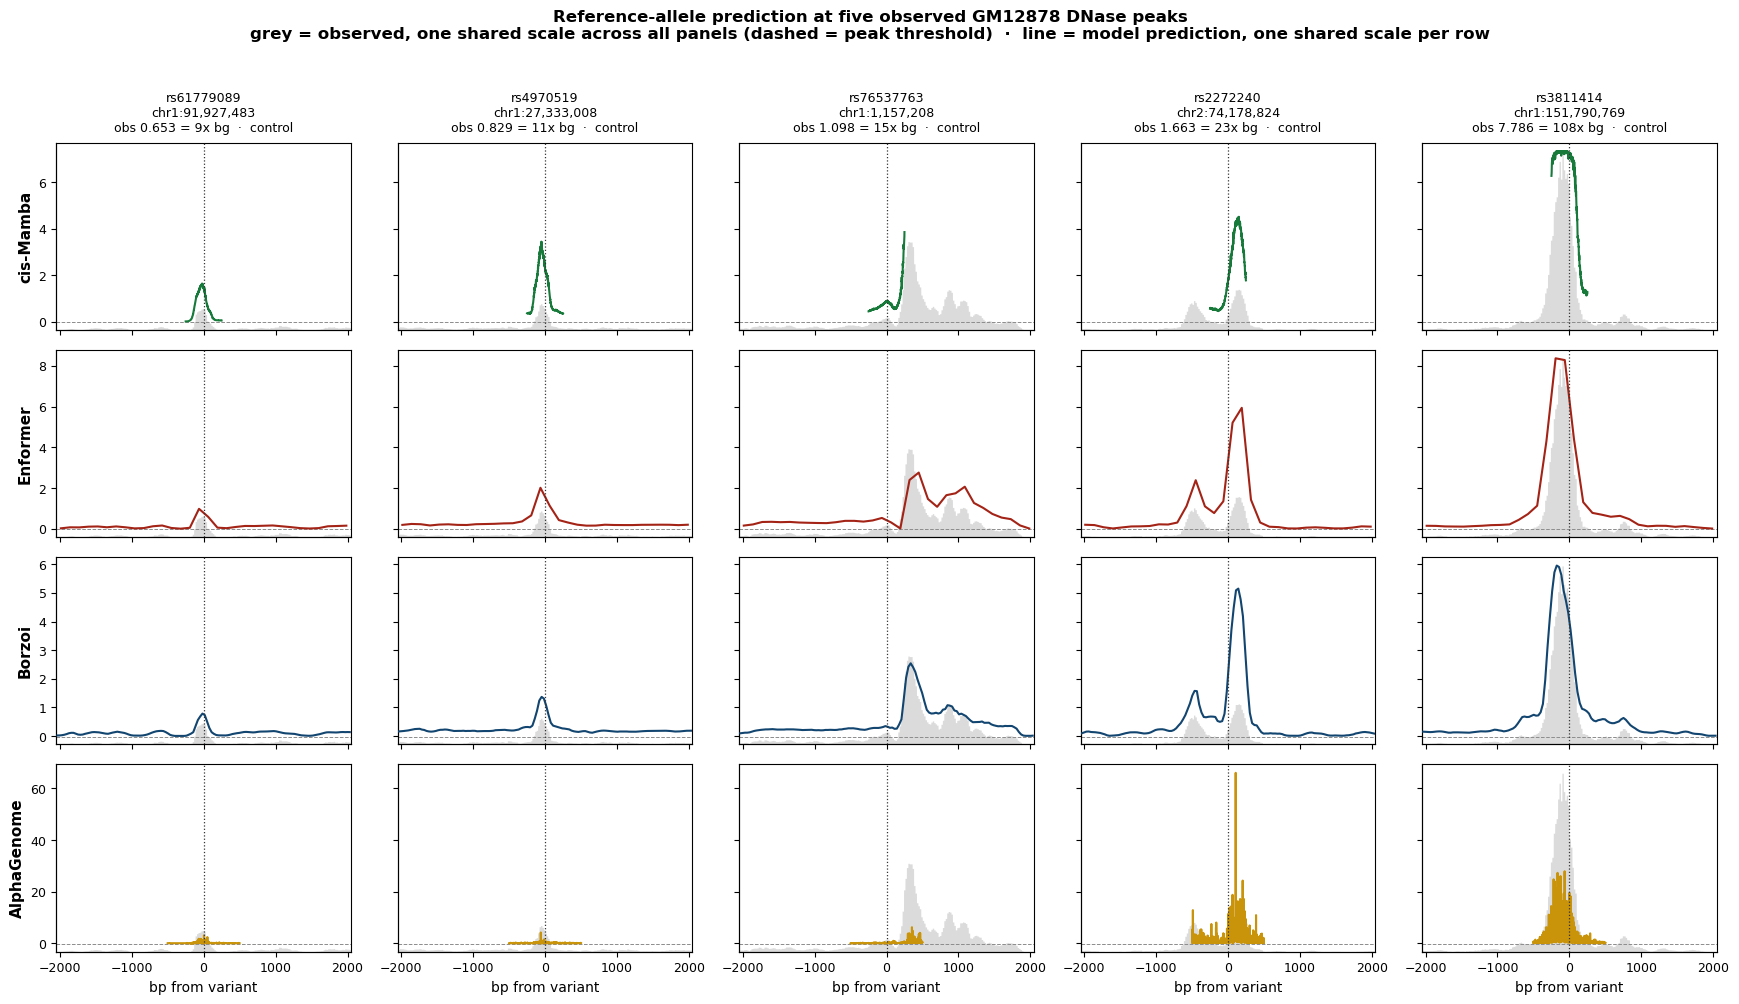

In [11]:
# --- threshold-setting diagnostic -------------------------------------------
# Ref-allele profiles at variants that sit in a REAL peak, found by scanning the
# observed npz directly. No model peak-calling yet -- this cell exists to pick a rule.
PROFILE_ARMS = [
    (0, 'nomlm_maskonly.npy',                1,   'cis-Mamba (GM12878 DNase)'),
    (1, 'enformer_dsqtl.npy',                128, 'Enformer (pretrained)'),
    (3, 'borzoi_dsqtl_pretrained_1288.npy',  32,  'Borzoi (pretrained, 1288)'),
    (7, 'alphagenome_dsqtl.zarr',            1,   'AlphaGenome'),   # 1 bp, no pooling
]

XSPAN = 4096                      # bp shown, centred on the variant
CENTRE = 256                      # half-width of the window that defines "in a peak"
N_EXAMPLES = 5
SEARCH_CHROMS = ['chr1', 'chr2']  # chromosomes scanned for examples; add more for a wider draw
BACKGROUND_N = 50_000             # random windows per chromosome, for the background
PEAK_Q = 0.99                     # background quantile above which a window is a peak
PICK = 'spread'                   # 'spread' across peak strength, or 'top' for the strongest
SEED = 0

CT_DIR = Path('/data1/lesliec/sarthak/data/DK_zarr/zarr_arrays/cell_type_arrays')
OBS_NPZ = {'GM12878': CT_DIR / 'GM12878_DNase.npz', 'HepG2': CT_DIR / 'HepG2_DNase.npz'}


def ref_profiles(f, rows):
    """Reference-allele profile (channel 0) for a handful of variants."""
    if f.endswith('.zarr'):
        m = metadata(DSQ / f)
        return np.stack([read_chunk(DSQ / f, m, (r, 0, 0))[0][:, 0].astype(np.float64) for r in rows])
    a = np.load(DSQ / f, mmap_mode='r')
    return np.asarray(a[list(rows)][:, :, 0], dtype=np.float64)


def scan_observed(track, chroms, half_centre, half_window, n_background, seed=0):
    """One pass per chromosome: every variant's window, its centre mean, and a background.

    The chromosome stays float16 and only the slices are widened, so peak memory is
    the ~500 MB chromosome rather than a float32 copy of it.
    """
    z = np.load(OBS_NPZ[track])
    rng = np.random.default_rng(seed)
    chrom_of, pos_of = v.chrom_hg38.to_numpy(), v.pos0_hg38.to_numpy()
    eligible = (v.mapping_status == 'mapped').to_numpy()
    rows, means, windows, background = [], [], [], []
    for ch in chroms:
        arr = z[ch][0]
        for r in np.flatnonzero(eligible & (chrom_of == ch)):
            lo, hi = int(pos_of[r]) - half_window, int(pos_of[r]) + half_window
            left, right = max(0, lo), min(len(arr), hi)
            w = np.zeros(2 * half_window, dtype=np.float32)
            w[left - lo:right - lo] = arr[left:right].astype(np.float32)
            rows.append(int(r))
            windows.append(w)
            means.append(float(w[half_window - half_centre:half_window + half_centre].mean()))
        starts = rng.integers(half_centre, len(arr) - half_centre, size=n_background)
        background.append(np.fromiter(
            (float(arr[s - half_centre:s + half_centre].astype(np.float32).mean()) for s in starts),
            dtype=np.float64, count=n_background))
        del arr
        print(f'  {ch}: {len(rows):,} variants so far', flush=True)
    return np.array(rows), np.array(means), np.stack(windows), np.concatenate(background)


obs_rows, obs_means, obs_windows, obs_bg = scan_observed(
    'GM12878', SEARCH_CHROMS, CENTRE, XSPAN // 2, BACKGROUND_N, SEED)

THRESH = float(np.quantile(obs_bg, PEAK_Q))
BG_MEDIAN = float(np.median(obs_bg))
in_peak = obs_means > THRESH
print(f'\nbackground   median {BG_MEDIAN:.4f}   {PEAK_Q:.0%} quantile {THRESH:.4f}')
print(f'variants     {len(obs_rows):,} on {", ".join(SEARCH_CHROMS)}')
print(f'in a peak    {int(in_peak.sum()):,}  ({in_peak.mean():.1%})')

# Pick examples spread across peak strength, so the panel shows marginal peaks as well
# as obvious ones -- a threshold that only works on the giants is not a threshold.
ranked = np.flatnonzero(in_peak)[np.argsort(obs_means[in_peak])]
sel = (ranked[np.linspace(0, len(ranked) - 1, N_EXAMPLES).round().astype(int)]
       if PICK == 'spread' else ranked[-N_EXAMPLES:])
picks = [int(obs_rows[s]) for s in sel]
obs = obs_windows[sel]
pick_means = obs_means[sel]

fig, axes = plt.subplots(len(PROFILE_ARMS), len(picks), sharex=True, sharey='row',
                         figsize=(3.5 * len(picks), 2.45 * len(PROFILE_ARMS)))
obs_ymax = float(obs.max())     # ONE grey scale for every panel, so columns are comparable
obs_x = np.arange(-(XSPAN // 2), XSPAN // 2)

diag_rows = []
for r, (idx, f, bp, name) in enumerate(PROFILE_ARMS):
    prof = ref_profiles(f, picks)
    x = (np.arange(prof.shape[1]) - prof.shape[1] / 2 + 0.5) * bp
    keep = np.abs(x) <= XSPAN / 2
    centre = np.abs(x) <= CENTRE
    for c in range(len(picks)):
        ax = axes[r, c]
        axo = ax.twinx()
        axo.fill_between(obs_x, obs[c], color='#C4C4C4', alpha=0.60, lw=0, zorder=1)
        axo.axhline(THRESH, color='#8C8C8C', ls='--', lw=0.7, zorder=2)
        axo.set_ylim(0, obs_ymax * 1.05)
        axo.set_yticks([])
        ax.plot(x[keep], prof[c][keep], color=A.FAMILY[ALL_ARMS[idx][1]], lw=1.5, zorder=3)
        ax.axvline(0, color='#333333', lw=0.9, ls=':', zorder=4)
        ax.set_xlim(-(XSPAN // 2), XSPAN // 2)
        ax.set_zorder(axo.get_zorder() + 1)
        ax.patch.set_visible(False)
        ax.tick_params(labelsize=9)
        ax.spines[['top', 'right']].set_visible(False)
        if c == 0:
            ax.set_ylabel(name.split(' (')[0], fontsize=11, weight='semibold')
        if r == 0:
            ax.set_title(f"{v.SNPname2.to_numpy()[picks[c]]}\n"
                         f"{v.chrom_hg38.to_numpy()[picks[c]]}:{int(v.pos0_hg38.to_numpy()[picks[c]]):,}\n"
                         f"obs {pick_means[c]:.3f} = {pick_means[c] / BG_MEDIAN:.0f}x bg  ·  "
                         f"{'dsQTL' if v.label_binary.to_numpy()[picks[c]] else 'control'}",
                         fontsize=9, pad=8)
        if r == len(PROFILE_ARMS) - 1:
            ax.set_xlabel('bp from variant', fontsize=10)
        diag_rows.append(dict(arm=name, variant=v.SNPname2.to_numpy()[picks[c]],
                              observed=pick_means[c],
                              centre=prof[c][centre].mean(),
                              window_median=np.median(prof[c][keep]),
                              window_max=prof[c][keep].max()))
fig.suptitle('Reference-allele prediction at five observed GM12878 DNase peaks\n'
             'grey = observed, one shared scale across all panels (dashed = peak threshold)  ·  '
             'line = model prediction, one shared scale per row',
             y=1.02, fontsize=12, weight='semibold')
fig.tight_layout()

diag = pd.DataFrame(diag_rows)
diag['centre_over_median'] = diag.centre / diag.window_median
diag.set_index(['arm', 'variant']).round(4)

### Reading it

`centre_over_median` is the 512 bp centre against the median of the same profile over the 4 kb
shown -- a crude local fold-enrichment, and the most likely basis for a unit-free peak rule. The
`observed` column is the same 512 bp mean in the true track, so a rule can be checked against it
directly. Two caveats before trusting the ratio:

- **cis-Mamba's window is only 500 bp**, so its "local background" is the peak itself and the
  ratio sits near 1 no matter what. It needs a different rule from the others -- most likely its
  absolute level against a genome-wide background from the same npz, which is the pass the next
  cell would do anyway.
- **AlphaGenome sees only +/-500 bp**, so like cis-Mamba it has little window left over for a
  local background, though at least its 1 kb is twice cis-Mamba's 500 bp.

Once you have picked a rule, the remaining panels are: how many dsQTLs sit in an observed GM12878
peak and how many of those peaks HepG2 shares, which arms call a peak where the truth has one, and
dsQTL AUPRC split by whether the arm found the peak in the first place.

---
# 6 - How many dsQTL variants sit in a peak?

The cell above looked at chr1 and chr2 to get a feel for the profiles. This one does the whole
genome and answers the question properly: of the 17,506 variants, how many are in an observed
GM12878 DNase peak and how many are not.

"Peak" is defined entirely from the npz, with no model and no FDR cache involved:

1. take the observed 512 bp mean centred on each variant;
2. sample random 512 bp windows on every chromosome to get a background distribution of what
   the track does at an arbitrary genomic position;
3. call the variant a peak when its window mean clears a quantile of that background.

Step 3 is the arbitrary one, which is why four thresholds are carried side by side rather than
one. They are chosen to span the plausible range:

| threshold | reading |
|---|---|
| `bg 90th pct` | above a typical genomic window -- permissive, will admit a lot of low, broad signal |
| `bg 99th pct` | the default used above; roughly "in the top 1% of the genome" |
| `bg 99.9th pct` | strict; only unambiguous peaks |
| `10x bg median` | fold-based rather than quantile-based, included because it does not depend on the shape of the background tail |

The first run reads all 24 chromosomes out of the 6.2 GB npz, a few minutes, and caches the
per-variant windows and the background to `dsQTL_benchmark8_cache/`. Later runs load the cache.

variants scanned      17,505 of 17,506  (unmapped variants have no position)
background windows    1,100,000
background median     0.0703
observed mean: min 0.0000  median 0.2386  max 9.4825



,threshold,value,peak,non_peak,pct_peak,dsqtl_in_peak,dsqtl_in_non_peak,prev_peak,prev_non_peak,enrichment
0,bg 90th pct,0.1843,11880,5625,67.8663,382,53,0.0322,0.0094,3.4127
1,10x bg median,0.7030,2278,15227,13.0134,171,264,0.0751,0.0173,4.3297
2,bg 99th pct,0.7091,2255,15250,12.8820,170,265,0.0754,0.0174,4.3384
3,bg 99.9th pct,2.7038,214,17291,1.2225,14,421,0.0654,0.0243,2.6869


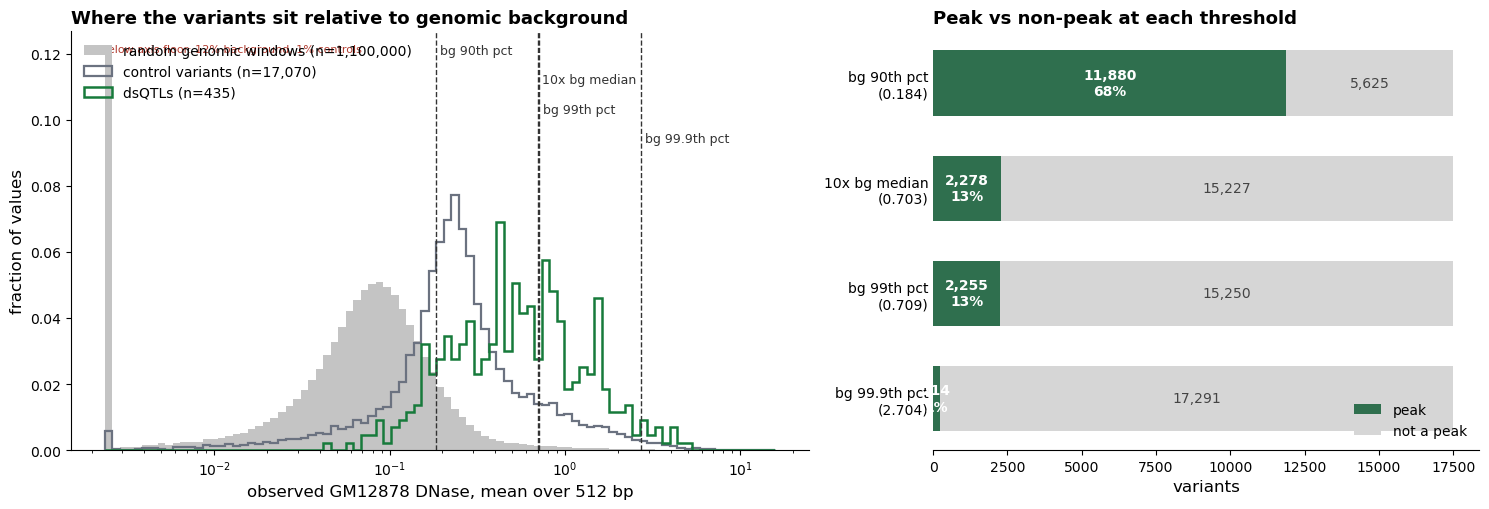

In [12]:
# Full-genome version of the two-chromosome scan above, cached to disk.
def observed_scan(track, half_centre=CENTRE, half_window=XSPAN // 2,
                  n_background=BACKGROUND_N, seed=SEED, use_cache=True):
    """Per-variant observed windows and a random-window background, genome-wide."""
    eligible = (v.mapping_status == 'mapped').to_numpy()
    chroms = sorted(set(v.chrom_hg38.to_numpy()[eligible]))
    path = CACHE / f'observed_{track}_c{half_centre}_w{half_window}_b{n_background}.npz'
    if use_cache and path.exists():
        with np.load(path) as d:
            return d['rows'], d['means'], d['windows'].astype(np.float32), d['background']
    rows, means, windows, background = scan_observed(
        track, chroms, half_centre, half_window, n_background, seed)
    if use_cache:
        np.savez_compressed(path, rows=rows, means=means,
                            windows=windows.astype(np.float16), background=background)
    return rows, means, windows.astype(np.float32), background


G_rows, G_means, G_windows, G_bg = observed_scan('GM12878')
G_label = v.label_binary.to_numpy()[G_rows]

THRESHOLDS = [
    ('bg 90th pct',   float(np.quantile(G_bg, 0.90))),
    ('bg 99th pct',   float(np.quantile(G_bg, 0.99))),
    ('bg 99.9th pct', float(np.quantile(G_bg, 0.999))),
    ('10x bg median', 10 * float(np.median(G_bg))),
]
THRESHOLDS.sort(key=lambda t: t[1])

summary = []
for name, t in THRESHOLDS:
    is_peak = G_means > t
    summary.append(dict(
        threshold=name, value=t,
        peak=int(is_peak.sum()), non_peak=int((~is_peak).sum()),
        pct_peak=100 * is_peak.mean(),
        dsqtl_in_peak=int(G_label[is_peak].sum()), dsqtl_in_non_peak=int(G_label[~is_peak].sum()),
        prev_peak=float(G_label[is_peak].mean()), prev_non_peak=float(G_label[~is_peak].mean()),
        enrichment=float(G_label[is_peak].mean() / G_label[~is_peak].mean())))
summary = pd.DataFrame(summary)

print(f'variants scanned      {len(G_rows):,} of {len(v):,}  (unmapped variants have no position)')
print(f'background windows    {len(G_bg):,}')
print(f'background median     {np.median(G_bg):.4f}')
print(f'observed mean: min {G_means.min():.4f}  median {np.median(G_means):.4f}  max {G_means.max():.4f}')
print()

fig, (axh, axb) = plt.subplots(1, 2, figsize=(15.0, 5.2),
                               gridspec_kw=dict(width_ratios=[1.35, 1]))

bins = log_bins(G_bg, G_means, nbins=90)
frac_hist(axh, G_bg, bins, color='#C4C4C4',
          label=f'random genomic windows (n={len(G_bg):,})', zorder=1)
frac_hist(axh, G_means[G_label == 0], bins, histtype='step',
          lw=1.6, color=A.C_REF, label=f'control variants (n={int((G_label == 0).sum()):,})', zorder=3)
frac_hist(axh, G_means[G_label == 1], bins, histtype='step',
          lw=1.8, color=A.C_OURS, label=f'dsQTLs (n={int(G_label.sum()):,})', zorder=4)
note_clipped(axh, bins, background=G_bg, controls=G_means[G_label == 0],
             dsQTLs=G_means[G_label == 1])
for i, (name, t) in enumerate(THRESHOLDS):
    axh.axvline(t, color='#333333', ls='--', lw=1.0, zorder=5)
    axh.text(t, axh.get_ylim()[1] * (0.97 - 0.07 * i), f' {name}', rotation=0, fontsize=9,
             va='top', ha='left', color='#333333')
axh.set_xscale('log')
axh.set_xlabel('observed GM12878 DNase, mean over 512 bp', fontsize=12)
axh.set_ylabel('fraction of values', fontsize=12)
axh.set_title('Where the variants sit relative to genomic background', loc='left',
              fontsize=13, weight='semibold')
axh.legend(fontsize=10, frameon=False)
axh.spines[['top', 'right']].set_visible(False)

y = np.arange(len(summary))
axb.barh(y, summary.peak, height=0.62, color='#2F6F4E', label='peak', zorder=3)
axb.barh(y, summary.non_peak, left=summary.peak, height=0.62, color='#D6D6D6',
         label='not a peak', zorder=3)
for r, row in enumerate(summary.itertuples()):
    axb.text(row.peak / 2, r, f'{row.peak:,}\n{row.pct_peak:.0f}%', ha='center', va='center',
             fontsize=10, color='white', weight='semibold')
    axb.text(row.peak + row.non_peak / 2, r, f'{row.non_peak:,}', ha='center', va='center',
             fontsize=10, color='#444444')
axb.set_yticks(y, [f'{n}\n({t:.3f})' for n, t in zip(summary.threshold, summary.value)])
axb.invert_yaxis()
axb.set_xlabel('variants', fontsize=12)
axb.set_title('Peak vs non-peak at each threshold', loc='left', fontsize=13, weight='semibold')
axb.legend(fontsize=10, frameon=False, loc='lower right')
axb.tick_params(axis='y', length=0, labelsize=10)
axb.spines[['top', 'right', 'left']].set_visible(False)
fig.tight_layout()

summary.round(4)

### Reading the table

`prev_peak` and `prev_non_peak` are the dsQTL rate inside and outside the peak set, and
`enrichment` is their ratio. A threshold that is doing real work should show dsQTLs concentrated
in the peak class -- these variants were mapped *as* accessibility QTLs, so they ought to live in
accessible chromatin. If enrichment barely moves as the threshold tightens, the extra strictness
is discarding real peaks rather than noise.

Note the two histograms of variants sit well to the right of the grey background: dsQTL candidates
are not random genomic positions, which is the conservative-null caveat from earlier made visible.

---
# 6b - What the thresholds actually cut

Four thresholds, and for each one the two dsQTLs that sit closest to it -- the highest-scoring
variant *below* the line and the lowest-scoring variant *above* it. These are the cases the
threshold is deciding, so if a boundary looks wrong here it is wrong.

Only true dsQTLs are used (`EXAMPLE_LABEL = 'dsqtl'`), since those are the variants whose peak
status the rest of the analysis depends on. Set it to `'all'` to draw from every variant.

Each row shares one y scale across its two panels, so below and above are directly comparable.
The dashed horizontal line is the threshold and the shaded band is the central 512 bp that the
mean is taken over -- the line is a level for that band, not a peak height, so a spiky profile can
sit below it and a broad flat one above.

variant           position  observed   ratio  \
threshold     side                                                          
bg 90th pct   just below    rs718341  chr13:110,683,381    0.1835  0.9956   
              just above  rs17091324   chr14:56,342,190    0.1888  1.0244   
10x bg median just below  rs11636046   chr15:22,949,325    0.6843  0.9734   
              just above   rs4804403    chr19:7,216,759    0.7042  1.0016   
bg 99th pct   just below   rs4804403    chr19:7,216,759    0.7042  0.9930   
              just above  rs73445583   chr22:50,606,317    0.7127  1.0050   
bg 99.9th pct just below   rs6603785     chr1:1,251,121    2.6950  0.9967   
              just above   rs3746988   chr21:45,556,196    2.7040  1.0001   

                          window_max  
threshold     side                    
bg 90th pct   just below      0.3044  
              just above      1.6523  
10x bg median just below      1.1191  
              just above      1.6826  
bg 99th pct   just below      1.6826  
              just above      1.0811  
bg 99.9th pct just below      6.0156  
              just above      6.4922

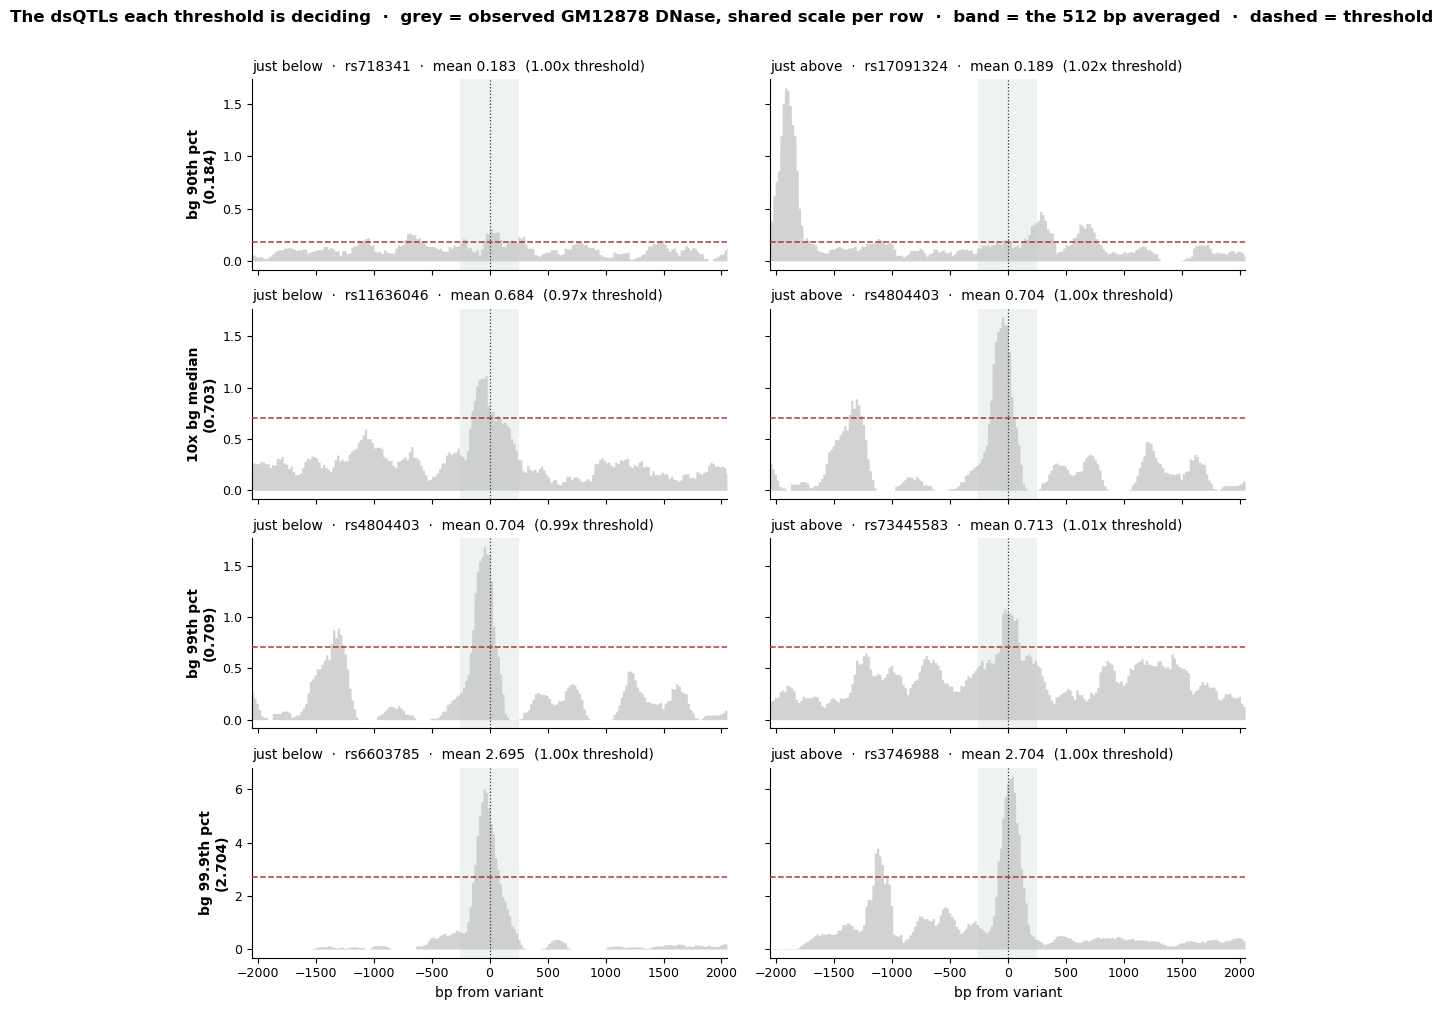

In [13]:
EXAMPLE_LABEL = 'dsqtl'   # 'dsqtl' = true dsQTLs only, 'all' = any scanned variant

pool = np.flatnonzero(G_label == 1) if EXAMPLE_LABEL == 'dsqtl' else np.arange(len(G_rows))
obs_x = np.arange(-(XSPAN // 2), XSPAN // 2)

fig, axes = plt.subplots(len(THRESHOLDS), 2, figsize=(11.0, 2.5 * len(THRESHOLDS)),
                         sharex=True, sharey='row')
edge_rows = []
for r, (name, t) in enumerate(THRESHOLDS):
    below = pool[G_means[pool] <= t]
    above = pool[G_means[pool] > t]
    picks = [(below[np.argmax(G_means[below])] if len(below) else None, 'just below'),
             (above[np.argmin(G_means[above])] if len(above) else None, 'just above')]
    for c, (p, side) in enumerate(picks):
        ax = axes[r, c]
        if p is None:
            ax.text(0.5, 0.5, f'no dsQTL {side} {name}', transform=ax.transAxes,
                    ha='center', va='center', fontsize=11, color='#888888')
            ax.set_axis_off()
            continue
        row = int(G_rows[p])
        ax.fill_between(obs_x, G_windows[p], color='#C4C4C4', alpha=0.75, lw=0, zorder=1)
        ax.axvspan(-CENTRE, CENTRE, color='#2F6F4E', alpha=0.08, lw=0, zorder=0)
        ax.axhline(t, color='#B03A2E', ls='--', lw=1.1, zorder=4)
        ax.axvline(0, color='#333333', lw=0.9, ls=':', zorder=5)
        ax.set_xlim(-(XSPAN // 2), XSPAN // 2)
        ax.tick_params(labelsize=9)
        ax.spines[['top', 'right']].set_visible(False)
        ax.set_title(f'{side}  ·  {v.SNPname2.to_numpy()[row]}  ·  '
                     f'mean {G_means[p]:.3f}  ({G_means[p] / t:.2f}x threshold)',
                     fontsize=10, loc='left', pad=6)
        if c == 0:
            ax.set_ylabel(f'{name}\n({t:.3f})', fontsize=10, weight='semibold')
        if r == len(THRESHOLDS) - 1:
            ax.set_xlabel('bp from variant', fontsize=10)
        edge_rows.append(dict(threshold=name, side=side, variant=v.SNPname2.to_numpy()[row],
                              position=f'{v.chrom_hg38.to_numpy()[row]}:{int(v.pos0_hg38.to_numpy()[row]):,}',
                              observed=float(G_means[p]), ratio=float(G_means[p] / t),
                              window_max=float(G_windows[p].max())))
fig.suptitle('The dsQTLs each threshold is deciding  ·  grey = observed GM12878 DNase, '
             'shared scale per row  ·  band = the 512 bp averaged  ·  dashed = threshold',
             y=1.005, fontsize=12, weight='semibold')
fig.tight_layout()

pd.DataFrame(edge_rows).set_index(['threshold', 'side']).round(4)

---
# 7 - A peak threshold for each model

`PEAK_T = 0.40` and `NULL_T = 0.10` on the observed GM12878 track. 0.40 calls 24% of variants
peaks, sits near the maximum of dsQTL enrichment, and implies roughly 3% of the genome is
accessible -- a plausible number, where 0.20 would have implied 8.4%. 0.10 is the floor below
which essentially nothing real lives: only 11 of 435 dsQTLs fall under it.

Those two numbers are in observed DNase units and mean nothing to a model that predicts in its
own scale. So each arm gets its own threshold, built the same way for all eight:

1. take the arm's **reference-allele** prediction, averaged over the common 512 bp centre
   (the alt channel is not used anywhere in this section);
2. collect those values at the variants the observed track says are confidently **not** peaks
   (`observed < NULL_T`) -- that is the arm's null, in its own units;
3. the arm's peak threshold is the 99th percentile of its own null.

In words: *an arm calls a peak when it predicts more signal than it does at 99% of places known to
have nothing.* Every arm is therefore held to the same 1% false-positive rate on known non-peaks,
which is what makes AlphaGenome's different scale stop mattering -- no unit conversion happens
anywhere.

The null is drawn from dsQTL candidate variants rather than random genomic positions, since only
variant windows were ever stored. Those candidates are enriched for regulatory sequence, so this
is a slightly conservative null -- fine for comparing arms to each other, which is the question.

First run reads each arm's array once to extract the 512 bp centre (the two Borzoi arms dominate
at 1.7 GB each) and caches the result.

**The last column is the ground truth put through the same comparison.** Observed GM12878 on top
defines the two classes, so its separation is perfect by construction; it is there as an anchor,
with `PEAK_T` dashed, `NULL_T` dotted, and the unused middle visible between them. Observed HepG2
below is *not* circular -- the classes are still GM12878's -- so it measures how much HepG2 signal
actually sits at a GM12878 peak, which is the ceiling any HepG2 readout could reach. It is given
the same null calibration as the arms, so its threshold is comparable to theirs.

That HepG2 threshold is not the same number as `HEP_T` in section 8. This one asks "is there more
HepG2 signal here than at a GM12878 non-peak"; section 8's is transferred by background percentile
and asks "is this a peak by HepG2's own genome-wide standard". Different questions, both wanted.

observed: 4,237 peaks (>0.4), 2,197 confident non-peaks (<0.1), 11,072 in between and unused here

                                 track  threshold  null_median  peak_median    TPR  FPR  AUROC
observed GM12878 (defines the classes)     0.4000       0.0508       0.7474 1.0000 0.00 1.0000
                        observed HepG2     0.3853       0.0506       0.6394 0.6344 0.01 0.9564



,arm,readout,threshold,null_median,peak_median,TPR,FPR,AUROC
0,cis-Mamba (GM12878 DNase logFC),GM12878,0.1859,0.0532,0.6948,0.9920,0.01,0.9990
1,cis-Mamba (HepG2 eval),HepG2,0.3228,0.0467,0.5938,0.7463,0.01,0.9812
2,Enformer (pretrained),GM12878,0.2987,0.0500,0.7000,0.9098,0.01,0.9949
3,Enformer (HepG2 eval),HepG2,0.5515,0.0484,0.5981,0.5181,0.01,0.9530
4,Borzoi (pretrained),GM12878,0.2242,0.0531,0.5636,0.9313,0.01,0.9957
5,Borzoi (HepG2 eval),HepG2,0.4962,0.0511,0.5336,0.5235,0.01,0.9547
6,AlphaGenome,GM12878,0.1150,0.0169,0.2475,0.7534,0.01,0.9790
7,AlphaGenome (HepG2 eval),HepG2,0.2289,0.0230,0.1144,0.3181,0.01,0.9305


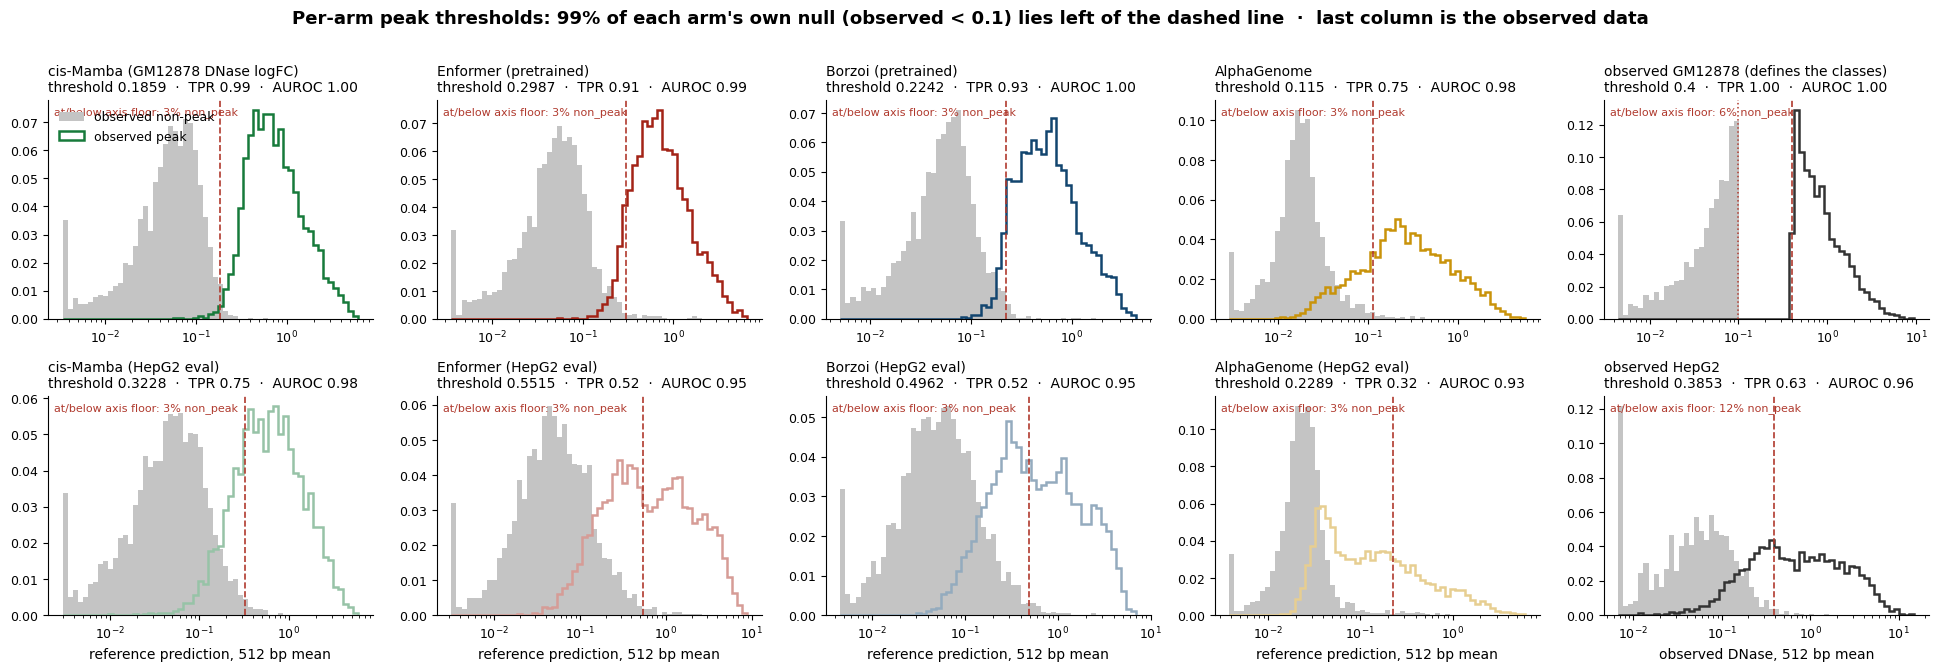

In [14]:
PEAK_T = 0.40    # observed GM12878 DNase: in a peak
NULL_T = 0.10    # observed GM12878 DNase: confidently not a peak
MODEL_NULL_Q = 0.99

# Observed signal indexed by variant row, so models and truth line up on one index.
obs_mean_all = np.full(len(v), np.nan)
obs_mean_all[G_rows] = G_means
is_peak_obs = obs_mean_all > PEAK_T     # NaN comparisons are False, so the unmapped variant
is_null_obs = obs_mean_all < NULL_T     # falls into neither class

def arm_bp(f):
    """Bin size in bp, from the same filename convention score_variants uses."""
    return 32 if 'borzoi' in f else (128 if 'enformer' in f else 1)


def centre_ref(f, half=CENTRE):
    """Reference-allele mean over the common +/-`half` bp window, one value per variant."""
    bp = arm_bp(f)
    if f.endswith('.zarr'):
        m = metadata(DSQ / f)
        n = m['shape'][1]
        keep = np.flatnonzero(np.abs((np.arange(n) - n / 2 + 0.5) * bp) <= half)
        return np.array([read_chunk(DSQ / f, m, (j, 0, 0))[0][keep, 0].mean()
                         for j in range(m['shape'][0])], dtype=np.float64)
    a = np.load(DSQ / f, mmap_mode='r')
    n = a.shape[1]
    keep = np.flatnonzero(np.abs((np.arange(n) - n / 2 + 0.5) * bp) <= half)
    return np.asarray(a[:, keep[0]:keep[-1] + 1, 0], dtype=np.float64).mean(axis=1)


def ref_centre_matrix(arm_idx, half=CENTRE, use_cache=True):
    """n_variants x n_arms of reference-allele centre means, cached."""
    names = [ALL_ARMS[i][0] for i in arm_idx]
    path = CACHE / f'ref_centre_{half}.npz'
    if use_cache and path.exists():
        with np.load(path, allow_pickle=False) as d:
            if list(json.loads(str(d['names']))) == names:
                return d['values']
    cols = []
    for i in arm_idx:
        cols.append(centre_ref(ALL_ARMS[i][2], half))
        print(f'  {ALL_ARMS[i][0]:28s} done', flush=True)
    values = np.column_stack(cols)
    if use_cache:
        np.savez_compressed(path, values=values, names=json.dumps(names))
    return values


REF = ref_centre_matrix(REDUCED)

rows = []
for k, i in enumerate(REDUCED):
    null_vals = REF[is_null_obs, k]
    peak_vals = REF[is_peak_obs, k]
    t = float(np.quantile(null_vals, MODEL_NULL_Q))
    both = is_null_obs | is_peak_obs
    rows.append(dict(
        arm=ALL_ARMS[i][0], readout='HepG2' if i in NEW else 'GM12878',
        threshold=t, null_median=float(np.median(null_vals)),
        peak_median=float(np.median(peak_vals)),
        TPR=float((peak_vals > t).mean()), FPR=float((null_vals > t).mean()),
        AUROC=metric_values(is_peak_obs[both].astype(int), REF[both, k])[1]))
model_thresholds = pd.DataFrame(rows)

print(f'observed: {int(is_peak_obs.sum()):,} peaks (>{PEAK_T}), '
      f'{int(is_null_obs.sum()):,} confident non-peaks (<{NULL_T}), '
      f'{int((~is_peak_obs & ~is_null_obs).sum()):,} in between and unused here')
print()

ncol = 5     # four model families, plus the observed tracks in the last column
fig, axes = plt.subplots(2, ncol, figsize=(3.9 * ncol, 6.6))
for k, i in enumerate(REDUCED):
    ax = axes[k % 2, k // 2]     # GM12878 on the top row, its HepG2 twin directly below
    null_vals, peak_vals = REF[is_null_obs, k], REF[is_peak_obs, k]
    bins = log_bins(null_vals, peak_vals)
    frac_hist(ax, null_vals, bins, color='#C4C4C4', label='observed non-peak', zorder=1)
    frac_hist(ax, peak_vals, bins, histtype='step', lw=1.8,
              color=arm_color(i), label='observed peak', zorder=3)
    note_clipped(ax, bins, non_peak=null_vals, peak=peak_vals)
    ax.axvline(model_thresholds.threshold[k], color='#B03A2E', ls='--', lw=1.2, zorder=4)
    ax.set_xscale('log')
    ax.set_title(f'{ALL_ARMS[i][0]}\nthreshold {model_thresholds.threshold[k]:.4g}  ·  '
                 f'TPR {model_thresholds.TPR[k]:.2f}  ·  AUROC {model_thresholds.AUROC[k]:.2f}',
                 fontsize=10, loc='left', pad=6)
    ax.tick_params(labelsize=9)
    ax.spines[['top', 'right']].set_visible(False)
    if k == 0:
        ax.legend(fontsize=9, frameon=False)
    if k % 2 == 1:
        ax.set_xlabel('reference prediction, 512 bp mean', fontsize=10)
# Ground truth in the last column, put through the same comparison as the arms.
# Top is observed GM12878, which *defines* the two classes -- its separation is perfect by
# construction and it is drawn only as an anchor, with both thresholds marked and the
# unused middle visible between them. Bottom is observed HepG2 on those same GM12878
# classes, which is not circular: it asks how much HepG2 signal sits at a GM12878 peak.
H_rows_obs, H_means_obs, _, _ = observed_scan('HepG2')
hep_mean_all = np.full(len(v), np.nan)
hep_mean_all[H_rows_obs] = H_means_obs

truth_rows = []
for r, (tname, vals) in enumerate([('observed GM12878 (defines the classes)', obs_mean_all),
                                   ('observed HepG2', hep_mean_all)]):
    ax = axes[r, ncol - 1]
    null_vals = vals[is_null_obs][np.isfinite(vals[is_null_obs])]
    peak_vals = vals[is_peak_obs][np.isfinite(vals[is_peak_obs])]
    # GM12878 keeps its defining cut; HepG2 gets the same null calibration the arms get.
    t = PEAK_T if r == 0 else float(np.quantile(null_vals, MODEL_NULL_Q))
    bins = log_bins(null_vals, peak_vals)
    frac_hist(ax, null_vals, bins, color='#C4C4C4', label='observed non-peak', zorder=1)
    frac_hist(ax, peak_vals, bins, histtype='step', lw=1.8,
              color='#333333', label='observed peak', zorder=3)
    note_clipped(ax, bins, non_peak=null_vals, peak=peak_vals)
    ax.axvline(t, color='#B03A2E', ls='--', lw=1.2, zorder=4)
    if r == 0:
        ax.axvline(NULL_T, color='#B03A2E', ls=':', lw=1.1, zorder=4)
    ax.set_xscale('log')
    ok = np.isfinite(vals) & (is_null_obs | is_peak_obs)
    auroc = metric_values(is_peak_obs[ok].astype(int), vals[ok])[1]
    ax.set_title(f'{tname}\nthreshold {t:.4g}  ·  TPR {(peak_vals > t).mean():.2f}  ·  '
                 f'AUROC {auroc:.2f}', fontsize=10, loc='left', pad=6)
    ax.tick_params(labelsize=9)
    ax.spines[['top', 'right']].set_visible(False)
    if r == 1:
        ax.set_xlabel('observed DNase, 512 bp mean', fontsize=10)
    truth_rows.append(dict(track=tname, threshold=t, null_median=float(np.median(null_vals)),
                           peak_median=float(np.median(peak_vals)),
                           TPR=float((peak_vals > t).mean()),
                           FPR=float((null_vals > t).mean()), AUROC=auroc))
truth_thresholds = pd.DataFrame(truth_rows)
print(truth_thresholds.round(4).to_string(index=False))
print()

fig.suptitle(f'Per-arm peak thresholds: {MODEL_NULL_Q:.0%} of each arm\'s own null '
             f'(observed < {NULL_T}) lies left of the dashed line  ·  '
             f'last column is the observed data',
             y=1.01, fontsize=13, weight='semibold')
fig.tight_layout()

model_thresholds.round(4)

### Reading it

`TPR` is the fraction of genuine observed peaks the arm calls a peak, at a 1% false-positive rate
on known non-peaks -- so the arms are directly comparable despite their units. `FPR` should land
on 0.01 by construction and is printed only as a check. `AUROC` is the threshold-free companion:
it asks whether the arm *ranks* peaks above non-peaks at all, regardless of where the line falls.

The two together separate two different failures. Low AUROC means the arm genuinely cannot tell
accessible from inaccessible sequence. High AUROC with low TPR means it ranks fine but its null is
wide relative to its peaks, so a fixed-FPR line costs it -- a calibration problem, not blindness.

---
# 8 - Do the arms even see the peak?

Restricted to **positive dsQTLs that sit in a real observed GM12878 peak** -- the variants where
the question "did it get the variant effect right" is meaningful at all, because there is
something there to get right.

For each of those variants, each of the eight arms either calls a peak from its reference
prediction or does not, using the per-arm thresholds above. Three views of the same matrix:

- **left** -- per-arm detection rate, GM12878 arm above its HepG2 twin;
- **middle** -- how many of the eight arms found each variant, which is the direct answer to
  "how many models predict a peak in the first place";
- **bottom** -- the full matrix, one column per variant, sorted by how many arms agree.

The observed GM12878 row is all peaks by construction -- it is the definition of the column set --
and is drawn only as an anchor. The observed **HepG2** row is not: it asks whether the peak is
shared between the two cell types, which is the thing that would let an arm reading a HepG2 track
succeed without knowing anything LCL-specific. Its threshold is transferred by background
percentile, not by raw value, since the two tracks have their own scales.

278 positive dsQTLs sit in an observed GM12878 peak (of 435 dsQTLs total)
HepG2 threshold 0.5690 = same background percentile (97.8225%) as GM12878 0.4
of these 278 GM12878 peaks, 122 (44%) are also HepG2 peaks


,arm,readout,found,of,rate
0,cis-Mamba (GM12878 DNase logFC),GM12878,269,278,0.9676
1,cis-Mamba (HepG2 eval),HepG2,188,278,0.6763
2,Enformer (pretrained),GM12878,254,278,0.9137
3,Enformer (HepG2 eval),HepG2,124,278,0.4460
4,Borzoi (pretrained),GM12878,255,278,0.9173
5,Borzoi (HepG2 eval),HepG2,122,278,0.4388
6,AlphaGenome,GM12878,223,278,0.8022
7,AlphaGenome (HepG2 eval),HepG2,85,278,0.3058


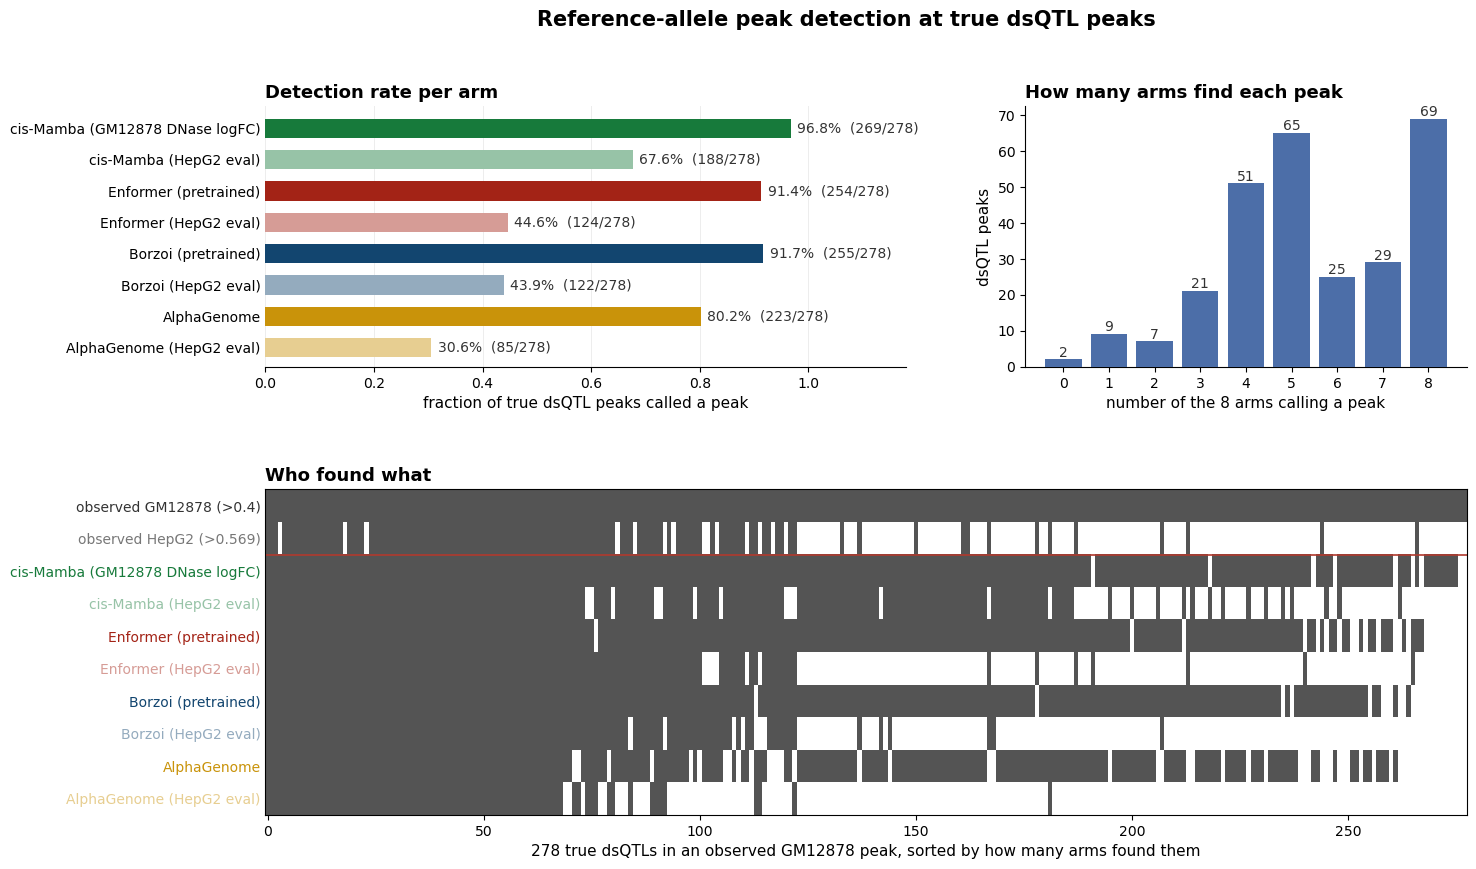

In [15]:
INCLUDE_HEPG2_OBSERVED = True   # second full npz scan, ~ a few minutes, then cached

target = is_peak_obs & (v.label_binary.to_numpy() == 1)
tgt = np.flatnonzero(target)
print(f'{len(tgt)} positive dsQTLs sit in an observed GM12878 peak '
      f'(of {int((v.label_binary.to_numpy() == 1).sum())} dsQTLs total)')

calls = np.column_stack([REF[tgt, k] > model_thresholds.threshold[k] for k in range(len(REDUCED))])
labels = [ALL_ARMS[i][0] for i in REDUCED]
colors = [arm_color(i) for i in REDUCED]

extra, extra_labels = [], []
if INCLUDE_HEPG2_OBSERVED:
    H_rows, H_means, _, H_bg = observed_scan('HepG2')
    # Transfer the threshold by background percentile: the two tracks have different scales.
    peak_q_bg = float((G_bg < PEAK_T).mean())
    HEP_T = float(np.quantile(H_bg, peak_q_bg))
    hep_all = np.full(len(v), np.nan)
    hep_all[H_rows] = H_means
    extra.append(hep_all[tgt] > HEP_T)
    extra_labels.append(f'observed HepG2 (>{HEP_T:.3f})')
    print(f'HepG2 threshold {HEP_T:.4f} = same background percentile ({peak_q_bg:.4%}) as '
          f'GM12878 {PEAK_T}')
    print(f'of these {len(tgt)} GM12878 peaks, {int(extra[0].sum())} '
          f'({extra[0].mean():.0%}) are also HepG2 peaks')

M = np.column_stack([np.ones(len(tgt), bool)] + extra + [calls[:, k] for k in range(calls.shape[1])])
row_labels = [f'observed GM12878 (>{PEAK_T})'] + extra_labels + labels
row_colors = ['#333333'] + ['#777777'] * len(extra) + colors
n_fixed = 1 + len(extra)

n_found = calls.sum(axis=1)
order = np.lexsort((-M[:, 0].astype(int), -n_found))

fig = plt.figure(figsize=(15.5, 9.2))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.25], width_ratios=[1.45, 1], hspace=0.42, wspace=0.22)

axr = fig.add_subplot(gs[0, 0])
rate = calls.mean(axis=0)
y = np.arange(len(labels))
axr.barh(y, rate, height=0.62, color=colors, zorder=3)
for j, r in enumerate(rate):
    axr.text(r + 0.012, j, f'{r:.1%}  ({int(calls[:, j].sum())}/{len(tgt)})', va='center',
             fontsize=10, color='#333333')
axr.set_yticks(y, labels)
axr.set_ylim(len(y) - 0.4, -0.7)
axr.set_xlim(0, 1.18)
axr.set_xlabel('fraction of true dsQTL peaks called a peak', fontsize=11)
axr.set_title('Detection rate per arm', loc='left', fontsize=13, weight='semibold')
axr.tick_params(axis='y', length=0, labelsize=10)
axr.grid(axis='x', color='#EDEDED', lw=0.7, zorder=0)
axr.set_axisbelow(True)
axr.spines[['top', 'right', 'left']].set_visible(False)

axn = fig.add_subplot(gs[0, 1])
counts = np.bincount(n_found, minlength=len(labels) + 1)
axn.bar(np.arange(len(counts)), counts, color='#4C6EA8', zorder=3)
for j, c in enumerate(counts):
    if c:
        axn.text(j, c, f'{c}', ha='center', va='bottom', fontsize=10, color='#333333')
axn.set_xticks(np.arange(len(counts)))
axn.set_xlabel('number of the 8 arms calling a peak', fontsize=11)
axn.set_ylabel('dsQTL peaks', fontsize=11)
axn.set_title('How many arms find each peak', loc='left', fontsize=13, weight='semibold')
axn.tick_params(labelsize=10)
axn.spines[['top', 'right']].set_visible(False)

axm = fig.add_subplot(gs[1, :])
axm.imshow(M[order].T, aspect='auto', interpolation='nearest', cmap='Greys', vmin=0, vmax=1.35)
axm.set_yticks(np.arange(len(row_labels)), row_labels, fontsize=10)
for tick, col in zip(axm.get_yticklabels(), row_colors):
    tick.set_color(col)
axm.axhline(n_fixed - 0.5, color='#B03A2E', lw=1.2)
axm.set_xlabel(f'{len(tgt)} true dsQTLs in an observed GM12878 peak, '
               f'sorted by how many arms found them', fontsize=11)
axm.set_title('Who found what', loc='left', fontsize=13, weight='semibold')
axm.tick_params(axis='y', length=0)
fig.suptitle('Reference-allele peak detection at true dsQTL peaks', y=0.985,
             fontsize=15, weight='semibold')

pd.DataFrame(dict(arm=labels, readout=model_thresholds.readout,
                  found=calls.sum(axis=0), of=len(tgt), rate=rate)).round(4)

---
# 9 - Peak detection, generic vs cell-type specific

Section 8 asked which arms see the peak. This asks whether they see *different kinds* of peak, on
the same stratification the AUPRC panels use: a GM12878 peak called in many cell types is generic,
one called in few is cell-type specific.

**The thresholds are the ones from section 7, unchanged.** Re-deriving a threshold inside each
stratum would make the two detection rates incomparable, and there is nothing to re-derive it
from anyway -- the null is built from non-peaks, which carry no specificity label.

Two stratifications, because they answer slightly different questions:

- **by breadth** -- the canonical one, from the FDR peak cache: below the median breadth of 68
  tracks is specific, above it is generic. This is the split panels 2 and 4 use, so the detection
  rates here sit directly against the AUPRC numbers there.
- **by HepG2 sharing** -- does this same peak exist in the observed HepG2 track? Cruder, two cell
  types rather than a breadth ladder, but it is the split that bears directly on the HepG2 arms:
  a peak present in both cell types is one a HepG2 readout can legitimately find.

The two use different peak definitions -- breadth comes from the FDR cache, sharing from the npz
thresholds -- so their strata do not partition the same variants. Counts are printed for both.

The specific stratum is small (a few dozen dsQTLs in a peak), so read a large gap as a signal and
a small one as nothing.

by breadth: Generic (broad peak) n=260, Cell-type specific (narrow peak) n=18  (of 278 dsQTLs in an observed peak)
by HepG2 sharing: Shared with HepG2 n=122, GM12878 only n=156  (of 278 dsQTLs in an observed peak)


,stratification,arm,readout,rate_a,rate_b,delta,n_a,n_b
0,by breadth,cis-Mamba (GM12878 DNase logFC),GM12878,0.9654,1.0000,-0.0346,260,18
1,by breadth,cis-Mamba (HepG2 eval),HepG2,0.6962,0.3889,0.3073,260,18
2,by breadth,Enformer (pretrained),GM12878,0.9231,0.7778,0.1453,260,18
3,by breadth,Enformer (HepG2 eval),HepG2,0.4769,0.0000,0.4769,260,18
4,by breadth,Borzoi (pretrained),GM12878,0.9231,0.8333,0.0897,260,18
5,by breadth,Borzoi (HepG2 eval),HepG2,0.4692,0.0000,0.4692,260,18
6,by breadth,AlphaGenome,GM12878,0.8038,0.7778,0.0261,260,18
7,by breadth,AlphaGenome (HepG2 eval),HepG2,0.3269,0.0000,0.3269,260,18
8,by HepG2 sharing,cis-Mamba (GM12878 DNase logFC),GM12878,1.0000,0.9423,0.0577,122,156
9,by HepG2 sharing,cis-Mamba (HepG2 eval),HepG2,0.8689,0.5256,0.3432,122,156


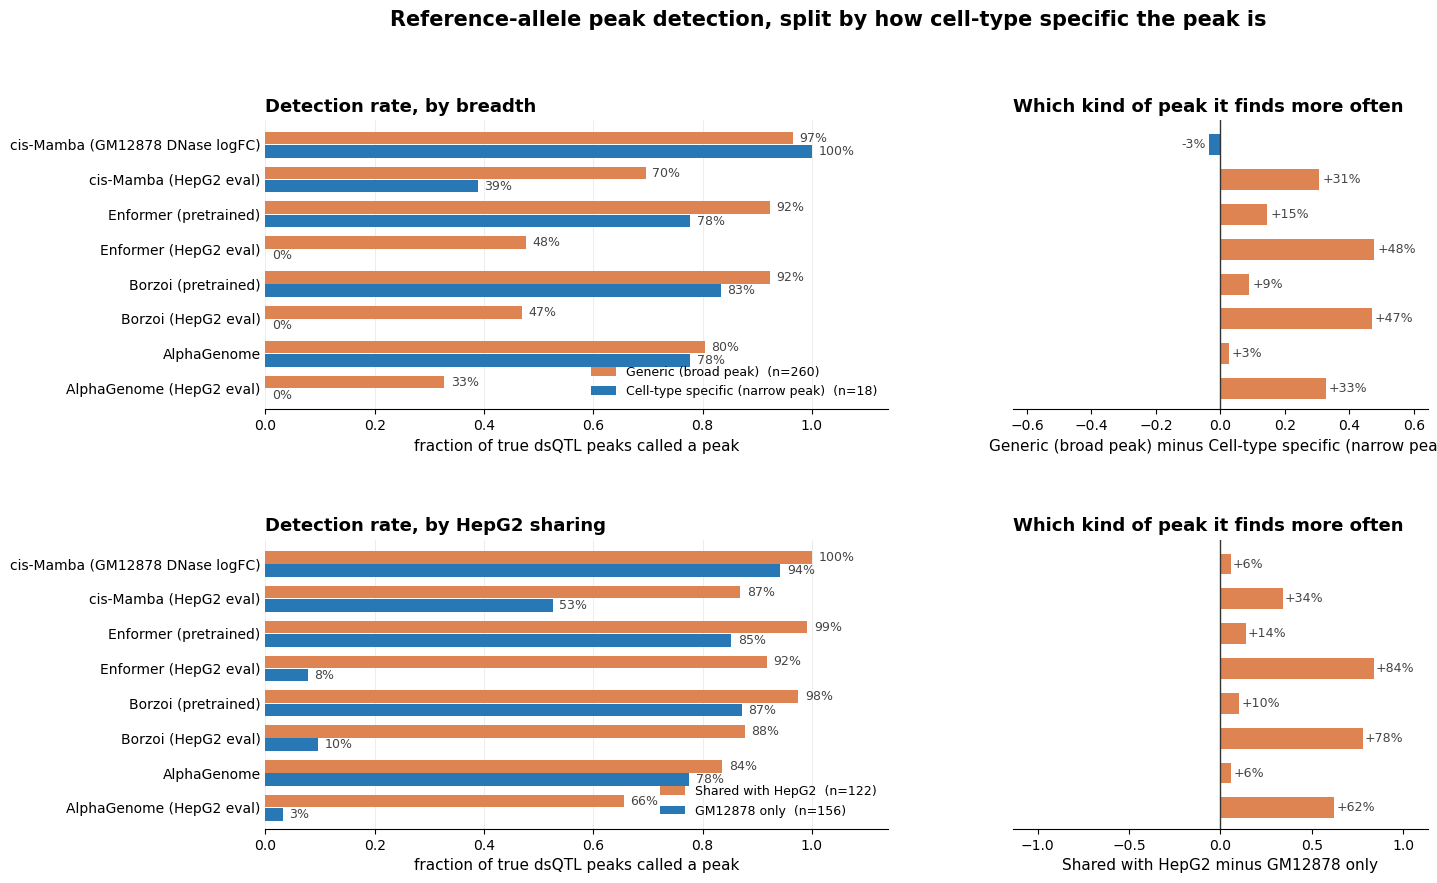

In [16]:
# Peak call for every variant under each arm's section-7 threshold.
call_all = REF > model_thresholds.threshold.to_numpy()[None, :]

spec = v[f'{DEFINITION}_specificity'].to_numpy()
strats = [('by breadth', 'Generic (broad peak)', 'Cell-type specific (narrow peak)',
           spec == 'low_specificity', spec == 'high_specificity')]
if INCLUDE_HEPG2_OBSERVED:
    hep_peak = hep_all > HEP_T
    strats.append(('by HepG2 sharing', 'Shared with HepG2', 'GM12878 only',
                   hep_peak, ~hep_peak & ~np.isnan(hep_all)))

C_GENERIC, C_SPECIFIC = '#DD8452', '#2878B5'
fig, axes = plt.subplots(len(strats), 2, figsize=(15.0, 4.6 * len(strats)),
                         gridspec_kw=dict(width_ratios=[1.5, 1], wspace=0.24, hspace=0.45),
                         squeeze=False)
y = np.arange(len(labels))
table = []
for s, (sname, name_a, name_b, mask_a, mask_b) in enumerate(strats):
    ia, ib = np.flatnonzero(target & mask_a), np.flatnonzero(target & mask_b)
    rate_a, rate_b = call_all[ia].mean(axis=0), call_all[ib].mean(axis=0)
    print(f'{sname}: {name_a} n={len(ia)}, {name_b} n={len(ib)}  '
          f'(of {int(target.sum())} dsQTLs in an observed peak)')

    ax = axes[s, 0]
    ax.barh(y - 0.19, rate_a, height=0.36, color=C_GENERIC, zorder=3,
            label=f'{name_a}  (n={len(ia)})')
    ax.barh(y + 0.19, rate_b, height=0.36, color=C_SPECIFIC, zorder=3,
            label=f'{name_b}  (n={len(ib)})')
    for j in range(len(labels)):
        ax.text(rate_a[j] + 0.012, j - 0.19, f'{rate_a[j]:.0%}', va='center', fontsize=9, color='#444444')
        ax.text(rate_b[j] + 0.012, j + 0.19, f'{rate_b[j]:.0%}', va='center', fontsize=9, color='#444444')
    ax.set_yticks(y, labels)
    ax.set_ylim(len(y) - 0.4, -0.7)
    ax.set_xlim(0, 1.14)
    ax.set_xlabel('fraction of true dsQTL peaks called a peak', fontsize=11)
    ax.set_title(f'Detection rate, {sname}', loc='left', fontsize=13, weight='semibold')
    ax.tick_params(axis='y', length=0, labelsize=10)
    ax.grid(axis='x', color='#EDEDED', lw=0.7, zorder=0)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.legend(fontsize=9, frameon=False, loc='lower right')

    axd = axes[s, 1]
    delta = rate_a - rate_b
    axd.barh(y, delta, height=0.6, zorder=3,
             color=[C_GENERIC if d > 0 else C_SPECIFIC for d in delta])
    axd.axvline(0, color='#333333', lw=1.0, zorder=4)
    for j, d in enumerate(delta):
        axd.text(d + (0.01 if d >= 0 else -0.01), j, f'{d:+.0%}', va='center',
                 ha='left' if d >= 0 else 'right', fontsize=9, color='#444444')
    axd.set_yticks(y, [])
    axd.set_ylim(len(y) - 0.4, -0.7)
    axd.set_xlim(-max(0.25, np.abs(delta).max() * 1.35), max(0.25, np.abs(delta).max() * 1.35))
    axd.set_xlabel(f'{name_a} minus {name_b}', fontsize=11)
    axd.set_title('Which kind of peak it finds more often', loc='left', fontsize=13, weight='semibold')
    axd.tick_params(axis='y', length=0)
    axd.spines[['top', 'right', 'left']].set_visible(False)

    for j, lab in enumerate(labels):
        table.append(dict(stratification=sname, arm=lab, readout=model_thresholds.readout[j],
                          rate_a=rate_a[j], rate_b=rate_b[j], delta=delta[j],
                          n_a=len(ia), n_b=len(ib)))
fig.suptitle('Reference-allele peak detection, split by how cell-type specific the peak is',
             y=1.0, fontsize=15, weight='semibold')

detect_by_stratum = pd.DataFrame(table)
detect_by_stratum.round(4)

### What to look for

A positive delta means the arm finds generic (or HepG2-shared) peaks more often than specific
ones. Some gap is expected everywhere -- broad peaks carry more signal and are easier for anything
to detect, and the same asymmetry is visible in the observed track itself.

The interesting quantity is therefore not the delta but how the delta **differs between an arm and
its HepG2 twin**. A HepG2 readout should be near its GM12878 twin on shared peaks and fall away on
GM12878-only ones; that is the whole premise of using it as a control. If a twin pair shows the
same delta, the GM12878 arm was not using cell-type-specific information either.

cis-Mamba is the one to read against that expectation rather than with it. Its accessibility input
is masked over only the central 1 kb, so on a shared peak the HepG2 track hands it the answer
through the flanks, and its HepG2 twin should track it closely almost everywhere. A *small* gap
there is the expected result, not evidence of cell-type-agnostic sequence modelling -- which is
exactly what the near-zero AUPRC gap in the pair table was already hinting at.

---
# 10 - Why detection falls but the effect survives

Section 9 shows the cis-Mamba HepG2 arm calling far fewer peaks, while the pair table in cell 19
shows its dsQTL AUPRC barely moving. The proposed explanation is that these measure different
things:

- **detection** thresholds the predicted *level* at the variant;
- **the dsQTL score** is `|log2(mean_ref / mean_alt)|`, a *ratio* within one locus, which is
  unchanged by any multiplicative rescaling of that locus.

and that the two inputs being varied are different channels. Between the two arms only the
accessibility input changes; between ref and alt only a single nucleotide changes, with the
accessibility tensor held identical (`dsqtl_onemodel.py` reuses `data` and rewrites one base).
So the HepG2 swap degrades the channel that sets the level, while the allelic effect is produced
entirely by the sequence channel.

Two cells test that. This one asks whether the distributions behave as predicted -- levels shifted
down for HepG2 arms, scores not -- and the next asks the same question variant by variant.

**Windows.** Levels use the common 512 bp centre so arms are comparable. Scores are taken from
`SCORES`, the benchmark's own values on each arm's native window, because those are literally what
the AUPRC panels ranked; the table reports the rank correlation between those and a 512 bp
recomputation so you can see whether the window choice matters.

The alternate channel has to be read off disk once for all eight arms, which is the same cost as
section 7 and is cached the same way.

,level_gm,level_hep,level_log2fc,level_spearman,score_gm,score_hep,score_spearman,min_chan_gm,min_chan_hep,score512_vs_native_gm,score512_vs_native_hep
family,,,,,,,,,,,
cis-Mamba,0.4386,0.3869,-0.1809,0.7765,0.3420,0.3337,0.7975,0.2428,0.2528,1.0000,1.0000
Enformer,0.4902,0.3063,-0.6783,0.6946,0.2483,0.0431,0.4292,0.2200,0.2572,0.8159,0.7809
Borzoi,0.4034,0.3133,-0.3646,0.7001,0.1982,0.0373,0.4412,0.1929,0.2678,0.8440,0.8109
AlphaGenome,0.1602,0.0691,-1.2124,0.5644,0.7516,0.1033,0.4337,0.0315,0.0408,0.9483,0.9244


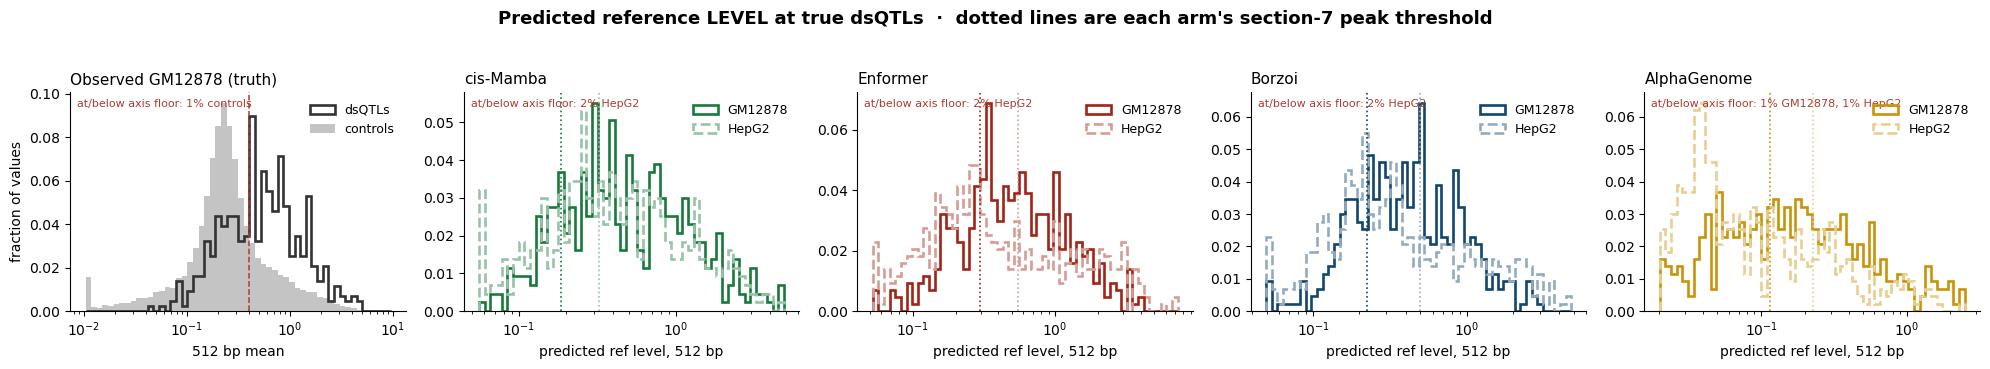

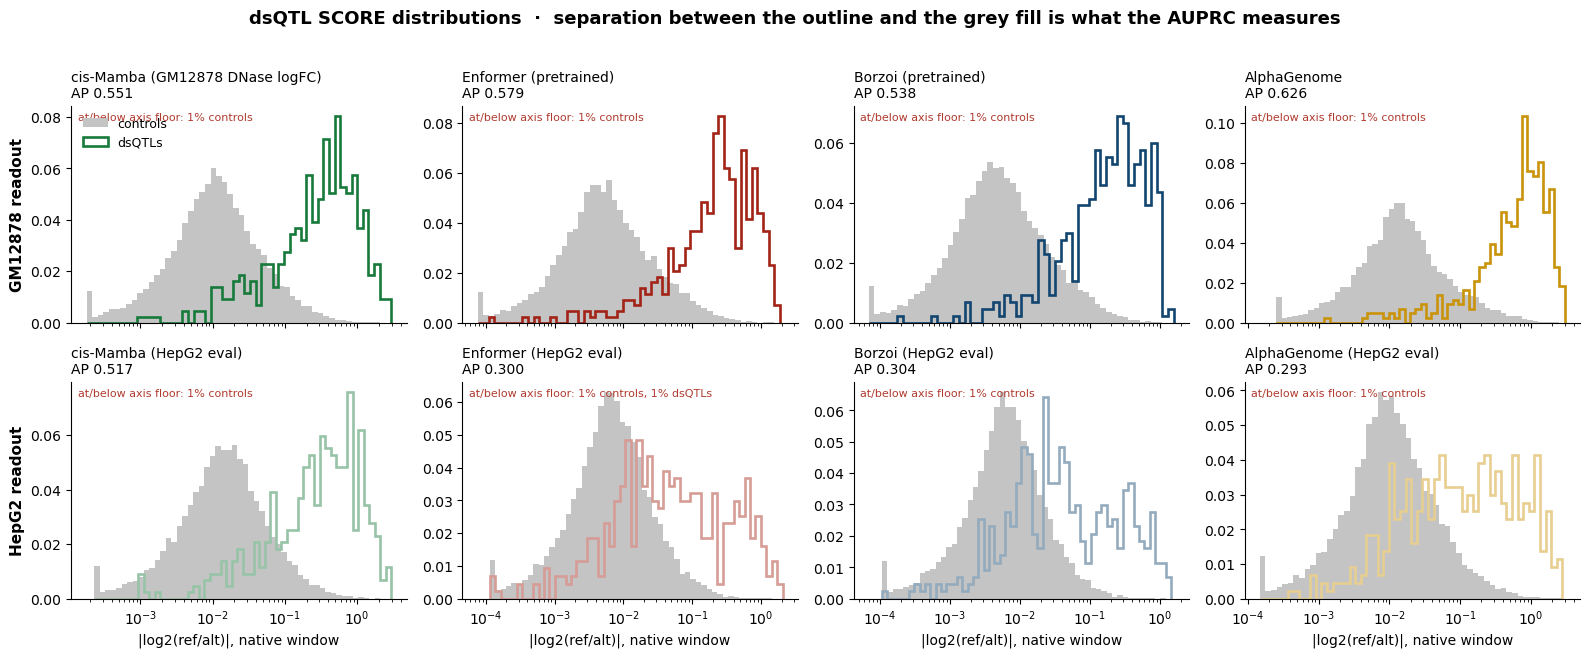

In [17]:
from scipy.stats import spearmanr

def centre_channel(f, chan, half=CENTRE):
    """centre_ref generalised to either channel: 0 = reference, 1 = alternate."""
    bp = arm_bp(f)
    if f.endswith('.zarr'):
        m = metadata(DSQ / f)
        n = m['shape'][1]
        keep = np.flatnonzero(np.abs((np.arange(n) - n / 2 + 0.5) * bp) <= half)
        return np.array([read_chunk(DSQ / f, m, (j, 0, 0))[0][keep, chan].mean()
                         for j in range(m['shape'][0])], dtype=np.float64)
    a = np.load(DSQ / f, mmap_mode='r')
    n = a.shape[1]
    keep = np.flatnonzero(np.abs((np.arange(n) - n / 2 + 0.5) * bp) <= half)
    return np.asarray(a[:, keep[0]:keep[-1] + 1, chan], dtype=np.float64).mean(axis=1)


def centre_matrix(arm_idx, chan, half=CENTRE, use_cache=True):
    names = [ALL_ARMS[i][0] for i in arm_idx]
    path = CACHE / f'centre_ch{chan}_{half}.npz'
    if use_cache and path.exists():
        with np.load(path, allow_pickle=False) as d:
            if list(json.loads(str(d['names']))) == names:
                return d['values']
    cols = []
    for i in arm_idx:
        cols.append(centre_channel(ALL_ARMS[i][2], chan, half))
        print(f'  {ALL_ARMS[i][0]:28s} alt done', flush=True)
    values = np.column_stack(cols)
    if use_cache:
        np.savez_compressed(path, values=values, names=json.dumps(names))
    return values


ALT = centre_matrix(REDUCED, 1)
SCORE512 = np.abs(np.log2(np.where(ALT > 0, REF, np.nan) / np.where(ALT > 0, ALT, np.nan)))

pos = v.label_binary.to_numpy() == 1
ctl = v.label_binary.to_numpy() == 0
PAIRS = [(2 * k, 2 * k + 1) for k in range(len(REDUCED) // 2)]
PAIR_NAMES = [ALL_ARMS[REDUCED[2 * k]][0].split(' (')[0] for k in range(len(PAIRS))]


def loghist(ax, values, bins, **kw):
    """Thin wrapper on frac_hist so both curves in a panel share one set of bins.

    The earlier version derived its own bins per call, so two overlaid histograms were
    drawn on different edges.
    """
    return frac_hist(ax, values, bins, **kw)


# --- levels: is the HepG2 arm attenuated? -----------------------------------
fig, axes = plt.subplots(1, len(PAIRS) + 1, figsize=(4.0 * (len(PAIRS) + 1), 3.5))
ax = axes[0]
tbins = log_bins(obs_mean_all[pos], obs_mean_all[ctl], nbins=55)
loghist(ax, obs_mean_all[pos], tbins, histtype='step', lw=1.9, color='#333333', label='dsQTLs')
loghist(ax, obs_mean_all[ctl], tbins, color='#C4C4C4', label='controls')
note_clipped(ax, tbins, dsQTLs=obs_mean_all[pos], controls=obs_mean_all[ctl])
ax.axvline(PEAK_T, color='#B03A2E', ls='--', lw=1.1)
ax.set_xscale('log')
ax.set_title('Observed GM12878 (truth)', fontsize=11, loc='left')
ax.set_xlabel('512 bp mean', fontsize=10)
ax.set_ylabel('fraction of values', fontsize=10)
ax.legend(fontsize=9, frameon=False)
ax.spines[['top', 'right']].set_visible(False)
for p, (kg, kh) in enumerate(PAIRS):
    ax = axes[p + 1]
    lbins = log_bins(REF[pos, kg], REF[pos, kh], nbins=55)
    loghist(ax, REF[pos, kg], lbins, histtype='step', lw=1.9, color=arm_color(REDUCED[kg]),
            label='GM12878')
    loghist(ax, REF[pos, kh], lbins, histtype='step', lw=1.9, ls='--', color=arm_color(REDUCED[kh]),
            label='HepG2')
    note_clipped(ax, lbins, GM12878=REF[pos, kg], HepG2=REF[pos, kh])
    ax.axvline(model_thresholds.threshold[kg], color=arm_color(REDUCED[kg]), ls=':', lw=1.2)
    ax.axvline(model_thresholds.threshold[kh], color=arm_color(REDUCED[kh]), ls=':', lw=1.2)
    ax.set_xscale('log')
    ax.set_title(PAIR_NAMES[p], fontsize=11, loc='left')
    ax.set_xlabel('predicted ref level, 512 bp', fontsize=10)
    ax.legend(fontsize=9, frameon=False)
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Predicted reference LEVEL at true dsQTLs  ·  dotted lines are each arm\'s '
             'section-7 peak threshold', y=1.04, fontsize=13, weight='semibold')
fig.tight_layout()

# --- scores: is the ratio preserved? ----------------------------------------
fig, axes = plt.subplots(2, len(PAIRS), figsize=(4.0 * len(PAIRS), 6.4), sharex='col')
for p, (kg, kh) in enumerate(PAIRS):
    for r, k in enumerate([kg, kh]):
        ax = axes[r, p]
        s = SCORES[:, REDUCED[k]]
        sbins = log_bins(s[ctl], s[pos], nbins=55)
        loghist(ax, s[ctl], sbins, color='#C4C4C4', label='controls')
        loghist(ax, s[pos], sbins, histtype='step', lw=1.9, color=arm_color(REDUCED[k]),
                label='dsQTLs')
        note_clipped(ax, sbins, controls=s[ctl], dsQTLs=s[pos])
        ax.set_xscale('log')
        ax.set_title(f'{ALL_ARMS[REDUCED[k]][0]}\nAP {pooled_reduced.set_index("idx").AP[REDUCED[k]]:.3f}',
                     fontsize=10, loc='left')
        ax.spines[['top', 'right']].set_visible(False)
        if p == 0:
            ax.set_ylabel(['GM12878 readout', 'HepG2 readout'][r], fontsize=11, weight='semibold')
        if r == 0 and p == 0:
            ax.legend(fontsize=9, frameon=False)
        if r == 1:
            ax.set_xlabel('|log2(ref/alt)|, native window', fontsize=10)
fig.suptitle('dsQTL SCORE distributions  ·  separation between the outline and the grey fill '
             'is what the AUPRC measures', y=1.02, fontsize=13, weight='semibold')
fig.tight_layout()

summary10 = []
for p, (kg, kh) in enumerate(PAIRS):
    both = np.isfinite(REF[:, kg]) & np.isfinite(REF[:, kh]) & (REF[:, kg] > 0) & (REF[:, kh] > 0)
    summary10.append(dict(
        family=PAIR_NAMES[p],
        level_gm=float(np.median(REF[pos, kg])), level_hep=float(np.median(REF[pos, kh])),
        level_log2fc=float(np.log2(np.median(REF[pos, kh]) / np.median(REF[pos, kg]))),
        level_spearman=float(spearmanr(REF[both, kg], REF[both, kh]).statistic),
        score_gm=float(np.nanmedian(SCORES[pos, REDUCED[kg]])),
        score_hep=float(np.nanmedian(SCORES[pos, REDUCED[kh]])),
        score_spearman=float(spearmanr(SCORES[:, REDUCED[kg]], SCORES[:, REDUCED[kh]]).statistic),
        min_chan_gm=float(np.median(np.minimum(REF[:, kg], ALT[:, kg]))),
        min_chan_hep=float(np.median(np.minimum(REF[:, kh], ALT[:, kh]))),
        score512_vs_native_gm=float(spearmanr(SCORE512[:, kg], SCORES[:, REDUCED[kg]],
                                              nan_policy='omit').statistic),
        score512_vs_native_hep=float(spearmanr(SCORE512[:, kh], SCORES[:, REDUCED[kh]],
                                               nan_policy='omit').statistic)))
pd.DataFrame(summary10).set_index('family').round(4)

### What confirms the explanation

`level_log2fc` strongly negative with `score_spearman` high is the predicted signature: the HepG2
arm predicts a lower level at the same places but ranks the allelic effects almost identically.
`level_spearman` says whether the level is merely rescaled (high) or genuinely rearranged (low) --
the first is consistent with the explanation, the second would refute it.

`min_chan_*` is the guard against the artifact: if the HepG2 arm's median `min(ref, alt)` is far
smaller, its log-ratios are being taken near the floor and could be inflated by noise rather than
signal. `score512_vs_native_*` near 1 means the window choice is not doing any of the work.

---
# 10b - The same variant, GM12878 against HepG2

The distributions above could hide a rearrangement: two sets could have the same shape while
individual variants move around inside them. This plots each variant once, its GM12878 value
against its HepG2 value, for both quantities.

The level row should sit **parallel to the identity line but below it** -- attenuation, with rank
order kept. A cloud with no structure would mean the HepG2 arm is predicting something unrelated,
and the surviving AUPRC would then need a different explanation.

The score row should sit **on** the identity line. Every point far off it is a variant where the
two arms genuinely disagree about the allelic effect.

A dashed fit in log space is drawn on the level row: a slope near 1 with a negative intercept is
pure attenuation, a slope below 1 is compression -- peaks pulled toward the baseline more than the
baseline moves, which is what makes a fixed threshold lose peaks while ratios survive.

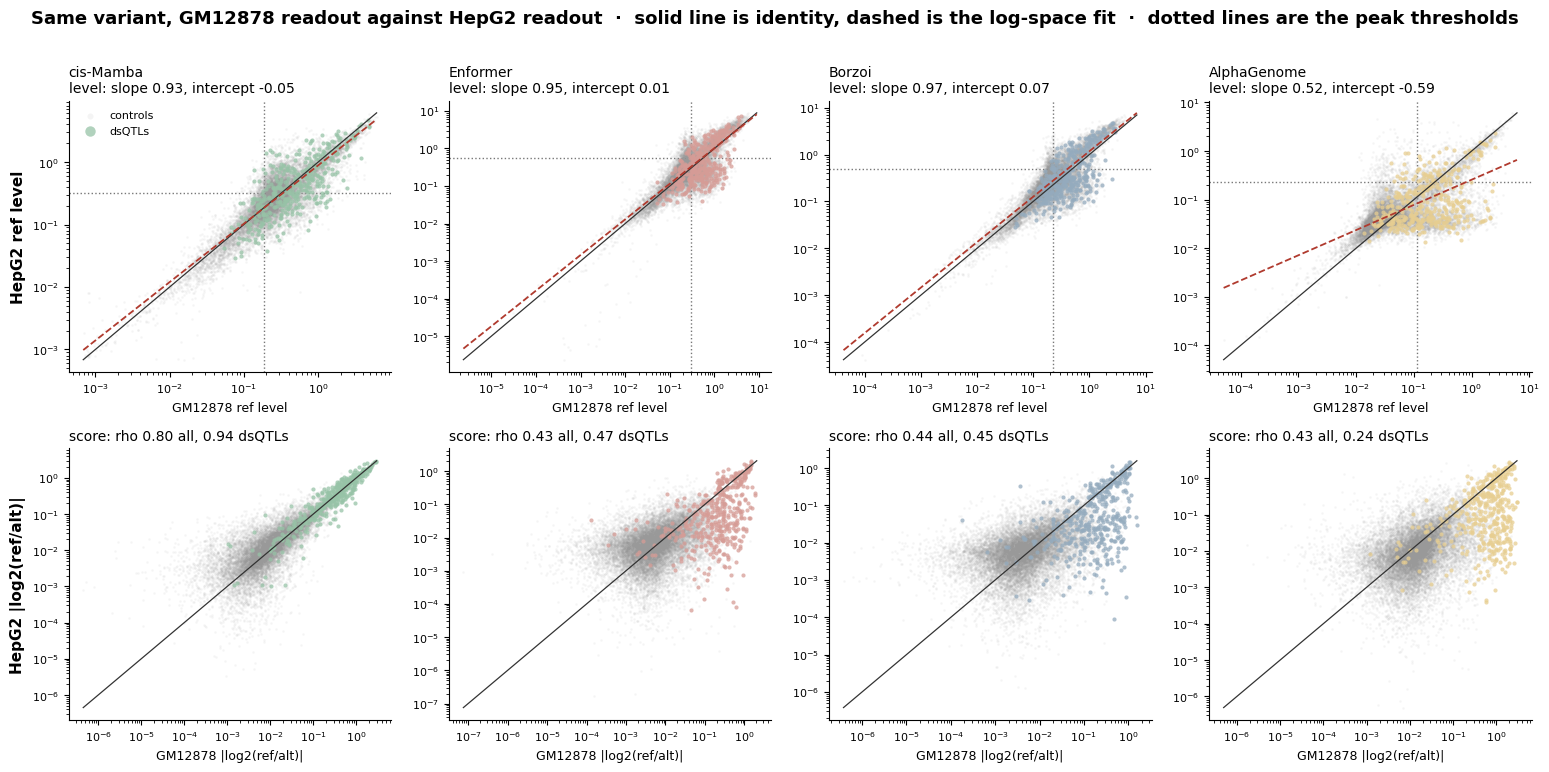

In [18]:
fig, axes = plt.subplots(2, len(PAIRS), figsize=(3.9 * len(PAIRS), 7.6))
for p, (kg, kh) in enumerate(PAIRS):
    # --- levels
    ax = axes[0, p]
    ok = (REF[:, kg] > 0) & (REF[:, kh] > 0)
    ax.scatter(REF[ok & ~pos, kg], REF[ok & ~pos, kh], s=3, alpha=0.10, color='#999999',
               lw=0, zorder=2, label='controls')
    ax.scatter(REF[ok & pos, kg], REF[ok & pos, kh], s=9, alpha=0.75,
               color=arm_color(REDUCED[kh]), lw=0, zorder=3, label='dsQTLs')
    lims = [min(REF[ok, kg].min(), REF[ok, kh].min()), max(REF[ok, kg].max(), REF[ok, kh].max())]
    ax.plot(lims, lims, color='#333333', lw=0.9, ls='-', zorder=4)
    slope, intercept = np.polyfit(np.log10(REF[ok, kg]), np.log10(REF[ok, kh]), 1)
    xs = np.array(lims)
    ax.plot(xs, 10 ** (intercept + slope * np.log10(xs)), color='#B03A2E', lw=1.3, ls='--', zorder=5)
    ax.axvline(model_thresholds.threshold[kg], color='#777777', ls=':', lw=1.0, zorder=1)
    ax.axhline(model_thresholds.threshold[kh], color='#777777', ls=':', lw=1.0, zorder=1)
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_title(f'{PAIR_NAMES[p]}\nlevel: slope {slope:.2f}, intercept {intercept:.2f}',
                 fontsize=10, loc='left')
    ax.set_xlabel('GM12878 ref level', fontsize=9)
    if p == 0:
        ax.set_ylabel('HepG2 ref level', fontsize=11, weight='semibold')
        ax.legend(fontsize=8, frameon=False, markerscale=2.5, loc='upper left')
    ax.tick_params(labelsize=8)
    ax.spines[['top', 'right']].set_visible(False)

    # --- scores
    ax = axes[1, p]
    sg, sh = SCORES[:, REDUCED[kg]], SCORES[:, REDUCED[kh]]
    ok = np.isfinite(sg) & np.isfinite(sh) & (sg > 0) & (sh > 0)
    ax.scatter(sg[ok & ~pos], sh[ok & ~pos], s=3, alpha=0.10, color='#999999', lw=0, zorder=2)
    ax.scatter(sg[ok & pos], sh[ok & pos], s=9, alpha=0.75, color=arm_color(REDUCED[kh]),
               lw=0, zorder=3)
    lims = [min(sg[ok].min(), sh[ok].min()), max(sg[ok].max(), sh[ok].max())]
    ax.plot(lims, lims, color='#333333', lw=0.9, zorder=4)
    rho = spearmanr(sg[ok], sh[ok]).statistic
    rho_pos = spearmanr(sg[ok & pos], sh[ok & pos]).statistic
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_title(f'score: rho {rho:.2f} all, {rho_pos:.2f} dsQTLs', fontsize=10, loc='left')
    ax.set_xlabel('GM12878 |log2(ref/alt)|', fontsize=9)
    if p == 0:
        ax.set_ylabel('HepG2 |log2(ref/alt)|', fontsize=11, weight='semibold')
    ax.tick_params(labelsize=8)
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Same variant, GM12878 readout against HepG2 readout  ·  solid line is identity, '
             'dashed is the log-space fit  ·  dotted lines are the peak thresholds',
             y=1.01, fontsize=13, weight='semibold')
fig.tight_layout()

---
# 7b - The same thresholds, split by peak specificity

Section 7 pooled every observed peak into one class. This splits that class in two, on the same
breadth stratification the AUPRC panels use, and leaves everything else identical -- same arms,
same 512 bp reference window, same thresholds from section 7. Nothing is recalibrated.

Each panel now carries three curves instead of two:

- **grey fill** -- the arm's prediction where the truth says nothing is there (`observed < NULL_T`);
- **orange outline** -- generic peaks, called in many cell types (`low_specificity`);
- **blue outline** -- cell-type specific peaks, called in few (`high_specificity`).

The dashed line is unchanged, so the two TPRs in each title are directly comparable: how many
generic peaks the arm finds, and how many specific ones, at the same 1% false-positive rate.

The two definitions do not nest -- specificity comes from the FDR cache's breadth ladder while the
peak class comes from the npz threshold -- so a variant can be an observed peak with no specificity
label. Those are dropped here and the surviving counts are printed.

The bottom-right panel is the one to read first. It is real HepG2 DNase at generic versus specific
GM12878 peaks, with no model involved: the ceiling on what any HepG2 readout could possibly find
in each stratum.

observed peaks 4,237  ->  generic 3,979, specific 239, no specificity label 19
true dsQTLs among them: generic 260, specific 18



,track,readout,threshold,TPR_generic,TPR_specific,gap,median_generic,median_specific
0,cis-Mamba (GM12878 DNase logFC),GM12878,0.1859,0.9925,0.9833,0.0092,0.7165,0.4891
1,cis-Mamba (HepG2 eval),HepG2,0.3228,0.7758,0.2510,0.5248,0.6285,0.2105
2,Enformer (pretrained),GM12878,0.2987,0.9191,0.7615,0.1576,0.7208,0.4514
3,Enformer (HepG2 eval),HepG2,0.5515,0.5489,0.0084,0.5405,0.6855,0.1124
4,Borzoi (pretrained),GM12878,0.2242,0.9409,0.7782,0.1627,0.5799,0.3369
5,Borzoi (HepG2 eval),HepG2,0.4962,0.5552,0.0084,0.5468,0.5992,0.1234
6,AlphaGenome,GM12878,0.1150,0.7499,0.8117,-0.0618,0.2472,0.2688
7,AlphaGenome (HepG2 eval),HepG2,0.2289,0.3380,0.0084,0.3297,0.1270,0.0314
8,observed GM12878 (defines the classes),observed,0.4000,1.0000,1.0000,0.0000,0.7581,0.6181
9,observed HepG2,observed,0.3853,0.6705,0.0418,0.6287,0.7286,0.1260


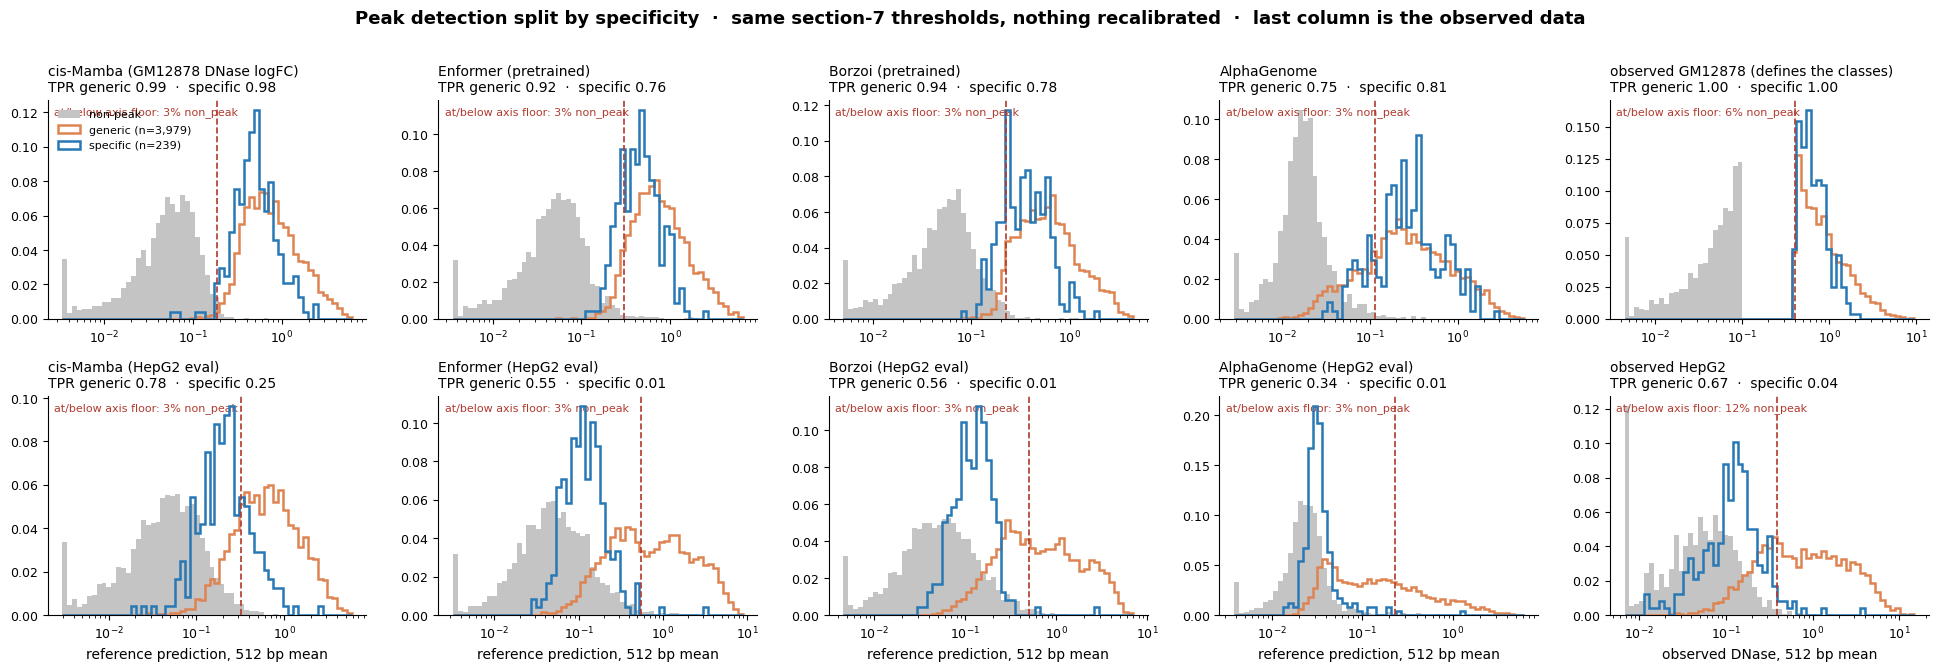

In [19]:
C_GENERIC, C_SPECIFIC = '#DD8452', '#2878B5'
spec_lab = v[f'{DEFINITION}_specificity'].to_numpy()
gen_mask = is_peak_obs & (spec_lab == 'low_specificity')
spc_mask = is_peak_obs & (spec_lab == 'high_specificity')
print(f'observed peaks {int(is_peak_obs.sum()):,}  ->  generic {int(gen_mask.sum()):,}, '
      f'specific {int(spc_mask.sum()):,}, '
      f'no specificity label {int((is_peak_obs & ~gen_mask & ~spc_mask).sum()):,}')
print(f'true dsQTLs among them: generic {int((gen_mask & (v.label_binary.to_numpy() == 1)).sum())}, '
      f'specific {int((spc_mask & (v.label_binary.to_numpy() == 1)).sum())}\n')

fig, axes = plt.subplots(2, ncol, figsize=(3.9 * ncol, 6.6))
strat_rows = []
for k, i in enumerate(REDUCED):
    ax = axes[k % 2, k // 2]
    null_vals, gen_vals, spc_vals = REF[is_null_obs, k], REF[gen_mask, k], REF[spc_mask, k]
    t = model_thresholds.threshold[k]
    bins = log_bins(null_vals, gen_vals, spc_vals)
    frac_hist(ax, null_vals, bins, color='#C4C4C4', label='non-peak', zorder=1)
    frac_hist(ax, gen_vals, bins, histtype='step', lw=1.8, color=C_GENERIC,
              label=f'generic (n={len(gen_vals):,})', zorder=3)
    frac_hist(ax, spc_vals, bins, histtype='step', lw=1.8, color=C_SPECIFIC,
              label=f'specific (n={len(spc_vals):,})', zorder=4)
    note_clipped(ax, bins, non_peak=null_vals, generic=gen_vals, specific=spc_vals)
    ax.axvline(t, color='#B03A2E', ls='--', lw=1.2, zorder=5)
    ax.set_xscale('log')
    ax.set_title(f'{ALL_ARMS[i][0]}\nTPR generic {(gen_vals > t).mean():.2f}  ·  '
                 f'specific {(spc_vals > t).mean():.2f}', fontsize=10, loc='left', pad=6)
    ax.tick_params(labelsize=9)
    ax.spines[['top', 'right']].set_visible(False)
    if k == 0:
        ax.legend(fontsize=8, frameon=False)
    if k % 2 == 1:
        ax.set_xlabel('reference prediction, 512 bp mean', fontsize=10)
    strat_rows.append(dict(track=ALL_ARMS[i][0], readout=model_thresholds.readout[k],
                           threshold=t, TPR_generic=float((gen_vals > t).mean()),
                           TPR_specific=float((spc_vals > t).mean()),
                           gap=float((gen_vals > t).mean() - (spc_vals > t).mean()),
                           median_generic=float(np.median(gen_vals)),
                           median_specific=float(np.median(spc_vals))))

for r, (tname, vals) in enumerate([('observed GM12878 (defines the classes)', obs_mean_all),
                                   ('observed HepG2', hep_mean_all)]):
    ax = axes[r, ncol - 1]
    finite = lambda m: vals[m][np.isfinite(vals[m])]
    null_vals, gen_vals, spc_vals = finite(is_null_obs), finite(gen_mask), finite(spc_mask)
    t = PEAK_T if r == 0 else float(np.quantile(null_vals, MODEL_NULL_Q))
    bins = log_bins(null_vals, gen_vals, spc_vals)
    frac_hist(ax, null_vals, bins, color='#C4C4C4', label='non-peak', zorder=1)
    frac_hist(ax, gen_vals, bins, histtype='step', lw=1.8, color=C_GENERIC, label='generic', zorder=3)
    frac_hist(ax, spc_vals, bins, histtype='step', lw=1.8, color=C_SPECIFIC, label='specific', zorder=4)
    note_clipped(ax, bins, non_peak=null_vals, generic=gen_vals, specific=spc_vals)
    ax.axvline(t, color='#B03A2E', ls='--', lw=1.2, zorder=5)
    ax.set_xscale('log')
    ax.set_title(f'{tname}\nTPR generic {(gen_vals > t).mean():.2f}  ·  '
                 f'specific {(spc_vals > t).mean():.2f}', fontsize=10, loc='left', pad=6)
    ax.tick_params(labelsize=9)
    ax.spines[['top', 'right']].set_visible(False)
    if r == 1:
        ax.set_xlabel('observed DNase, 512 bp mean', fontsize=10)
    strat_rows.append(dict(track=tname, readout='observed', threshold=t,
                           TPR_generic=float((gen_vals > t).mean()),
                           TPR_specific=float((spc_vals > t).mean()),
                           gap=float((gen_vals > t).mean() - (spc_vals > t).mean()),
                           median_generic=float(np.median(gen_vals)),
                           median_specific=float(np.median(spc_vals))))
fig.suptitle('Peak detection split by specificity  ·  same section-7 thresholds, nothing '
             'recalibrated  ·  last column is the observed data',
             y=1.01, fontsize=13, weight='semibold')
fig.tight_layout()

detection_by_specificity = pd.DataFrame(strat_rows)
detection_by_specificity.round(4)

### What 7b answers

`gap` is how much better an arm is at finding generic peaks than specific ones. Some gap is
expected everywhere -- the observed row shows specific peaks carry less signal even in the truth --
so the observed rows are the baseline every model row should be read against.

The comparison that matters is a GM12878 arm against its HepG2 twin **within** a stratum. If a
HepG2 readout matches its twin on generic peaks and collapses on specific ones, the arm's
representation of accessibility is genuinely cell-type-conditioned. If it collapses on both by the
same amount, the HepG2 swap is costing it something unrelated to specificity.

---
# 10c - Pairwise level and score, split by specificity

Section 10b plotted every variant with dsQTLs highlighted. This restricts to variants in an
observed GM12878 peak that carry a specificity label, and colours by stratum instead.

The point is the observation from section 10 -- that levels are largely preserved between the two
readouts for Borzoi and Enformer while scores are not -- checked separately in each stratum.

- **top row, levels.** A per-stratum fit in log space. If the specific points sit further below
  the identity line than the generic ones, the arm is predicting less accessibility in HepG2
  exactly where the peak is LCL-specific, which is the correct behaviour and the thing that should
  make its dsQTL scores unreliable there.
- **bottom row, scores.** Distance from the identity line is disagreement about the allelic
  effect. The annotation gives the per-stratum rank correlation and the median log2 change in
  score, so a stratum where the two readouts rank variants differently is visible even when the
  cloud looks similar.

n  level_slope  level_intercept  level_log2fc  \
family      stratum                                                      
cis-Mamba   generic   3979       0.9044          -0.1057       -0.1890   
            specific   239       0.6673          -0.4730       -1.2165   
Enformer    generic   3979       1.0527          -0.0341       -0.0724   
            specific   239       0.1602          -0.8735       -2.0056   
Borzoi      generic   3979       1.0291           0.0282        0.0470   
            specific   239       0.2745          -0.7973       -1.4495   
AlphaGenome generic   3979       0.5400          -0.5121       -0.9608   
            specific   239       0.0647          -1.4347       -3.0963   

                      score_spearman  score_log2fc  
family      stratum                                 
cis-Mamba   generic           0.8689        0.0543  
            specific          0.9017        0.0109  
Enformer    generic           0.4674       -0.2404  
            specific          0.1899       -2.1872  
Borzoi      generic           0.4891       -0.3706  
            specific          0.2929       -1.9105  
AlphaGenome generic           0.4684       -0.4922  
            specific          0.3251       -3.1653

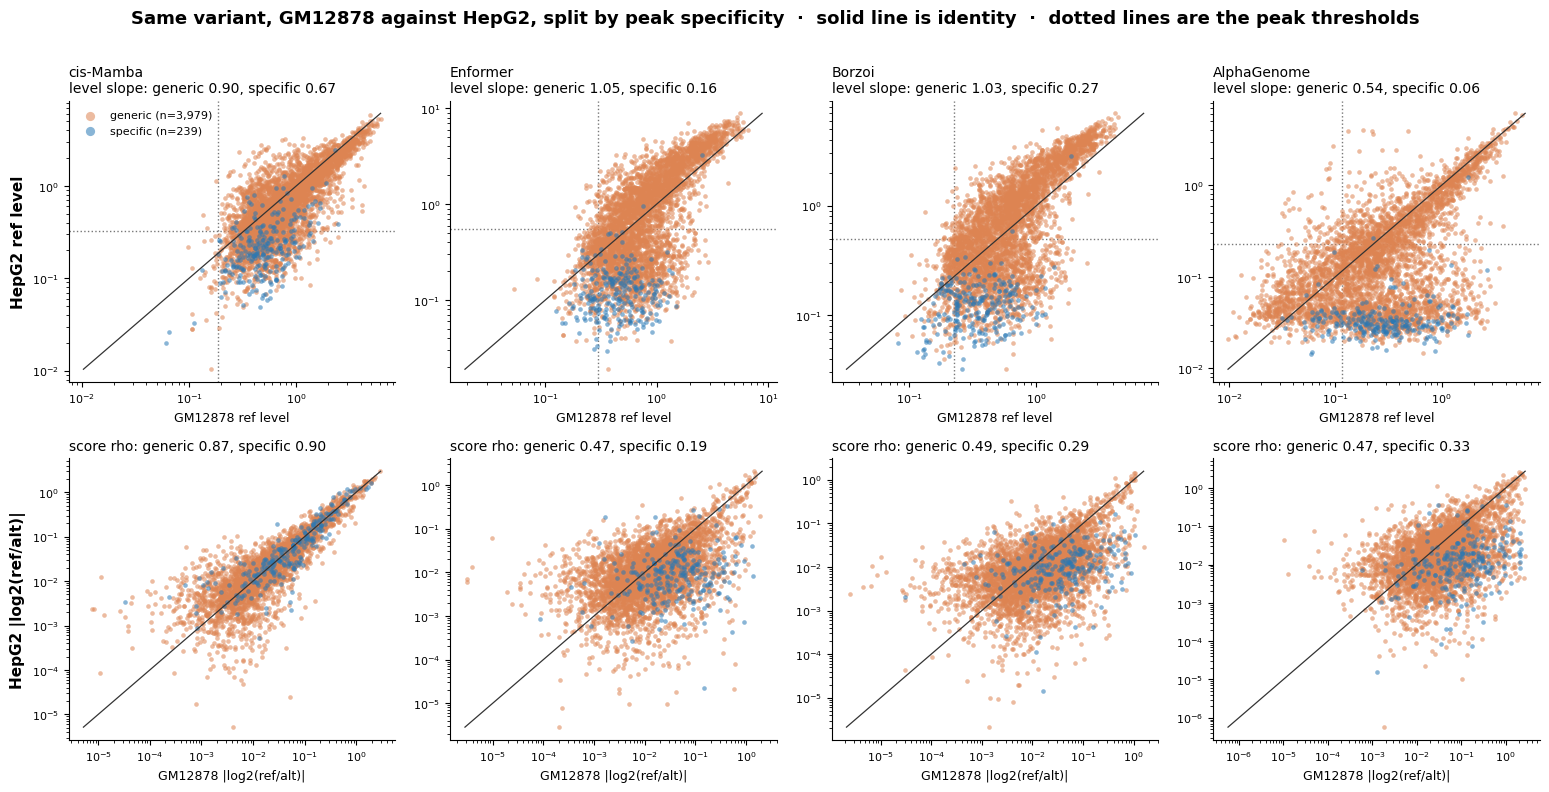

In [20]:
PAIRS_C = [(2 * k, 2 * k + 1) for k in range(len(REDUCED) // 2)]
NAMES_C = [ALL_ARMS[REDUCED[2 * k]][0].split(' (')[0] for k in range(len(PAIRS_C))]
STRATA_C = [('generic', gen_mask, C_GENERIC), ('specific', spc_mask, C_SPECIFIC)]

fig, axes = plt.subplots(2, len(PAIRS_C), figsize=(3.9 * len(PAIRS_C), 7.8))
rows10c = []
for p, (kg, kh) in enumerate(PAIRS_C):
    axl, axs = axes[0, p], axes[1, p]
    sg, sh = SCORES[:, REDUCED[kg]], SCORES[:, REDUCED[kh]]
    for sname, mask, colr in STRATA_C:
        ok = mask & (REF[:, kg] > 0) & (REF[:, kh] > 0)
        axl.scatter(REF[ok, kg], REF[ok, kh], s=11, alpha=0.55, color=colr, lw=0, zorder=3,
                    label=f'{sname} (n={int(ok.sum()):,})')
        slope, intercept = np.polyfit(np.log10(REF[ok, kg]), np.log10(REF[ok, kh]), 1)
        oks = mask & np.isfinite(sg) & np.isfinite(sh) & (sg > 0) & (sh > 0)
        axs.scatter(sg[oks], sh[oks], s=11, alpha=0.55, color=colr, lw=0, zorder=3)
        rows10c.append(dict(
            family=NAMES_C[p], stratum=sname, n=int(ok.sum()),
            level_slope=float(slope), level_intercept=float(intercept),
            level_log2fc=float(np.log2(np.median(REF[ok, kh]) / np.median(REF[ok, kg]))),
            score_spearman=float(spearmanr(sg[oks], sh[oks]).statistic),
            score_log2fc=float(np.median(np.log2(sh[oks] / sg[oks])))))
    for ax, xs, ys in [(axl, REF[:, kg], REF[:, kh]), (axs, sg, sh)]:
        m = (gen_mask | spc_mask) & np.isfinite(xs) & np.isfinite(ys) & (xs > 0) & (ys > 0)
        lims = [min(xs[m].min(), ys[m].min()), max(xs[m].max(), ys[m].max())]
        ax.plot(lims, lims, color='#333333', lw=0.9, zorder=4)
        ax.set_xscale('log'); ax.set_yscale('log')
        ax.tick_params(labelsize=8)
        ax.spines[['top', 'right']].set_visible(False)
    d = {r['stratum']: r for r in rows10c[-2:]}
    axl.axvline(model_thresholds.threshold[kg], color='#777777', ls=':', lw=1.0, zorder=1)
    axl.axhline(model_thresholds.threshold[kh], color='#777777', ls=':', lw=1.0, zorder=1)
    axl.set_title(f'{NAMES_C[p]}\nlevel slope: generic {d["generic"]["level_slope"]:.2f}, '
                  f'specific {d["specific"]["level_slope"]:.2f}', fontsize=10, loc='left')
    axs.set_title(f'score rho: generic {d["generic"]["score_spearman"]:.2f}, '
                  f'specific {d["specific"]["score_spearman"]:.2f}', fontsize=10, loc='left')
    axl.set_xlabel('GM12878 ref level', fontsize=9)
    axs.set_xlabel('GM12878 |log2(ref/alt)|', fontsize=9)
    if p == 0:
        axl.set_ylabel('HepG2 ref level', fontsize=11, weight='semibold')
        axs.set_ylabel('HepG2 |log2(ref/alt)|', fontsize=11, weight='semibold')
        axl.legend(fontsize=8, frameon=False, markerscale=2.0, loc='upper left')
fig.suptitle('Same variant, GM12878 against HepG2, split by peak specificity  ·  '
             'solid line is identity  ·  dotted lines are the peak thresholds',
             y=1.01, fontsize=13, weight='semibold')
fig.tight_layout()

pairwise_by_specificity = pd.DataFrame(rows10c).set_index(['family', 'stratum'])
pairwise_by_specificity.round(4)